# 01. EDA (train만)

- 담당: **② 홍시윤 (데이터·피처)** (이 파일은 담당자만 수정)
- 기록 파일: `experiments/log_H_data.csv`

### 할 일
- [ ] 클래스 분포, 소수 클래스 확인
- [ ] 환자별 변이 개수 분포, 클래스별 차이
- [ ] 자주 나오는 변이·유전자, 클래스별 특징 유전자
- [ ] 발표용 그래프는 `reports/figures/`에 저장

**test는 탐색하지 않아요.** test에서 얻은 정보를 전처리에 쓰면 누수예요.

> **규칙:** 전처리는 Pipeline 안에 / test는 보지 않기 / 점수는 `run_cv()`로 / 결과는 `log_result()`로 기록 / 자세한 규칙은 `docs/coding_rules.md`

## 0. 환경 설정 (수정하지 말고 그대로 실행)
Colab은 구글 드라이브 `내 드라이브`에 레포 폴더(`ah07-cancer-subtype`, 안에 `data/` 포함)를 두면 돼요.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = "/content/drive/MyDrive/ah07-cancer-subtype"  # 드라이브에 둔 레포 폴더
else:
    REPO_DIR = os.path.abspath(os.path.join("..", ".."))  # notebooks/이니셜_역할/ 폴더 기준

# 경로 확인: 여기서 멈추면 폴더 위치나 이름을 확인해 주세요
assert os.path.isdir(os.path.join(REPO_DIR, "src")), (
    f"src 폴더를 찾을 수 없어요: {REPO_DIR}\n"
    "→ 드라이브 '내 드라이브' 바로 아래에 'ah07-cancer-subtype' 폴더가 있는지, "
    "ZIP을 풀 때 폴더가 두 번 겹치지 않았는지(ah07-cancer-subtype/ah07-cancer-subtype-dev) 확인")
assert os.path.isfile(os.path.join(REPO_DIR, "data", "train.csv")), (
    "data/train.csv 가 없어요 → 데이콘 csv 3개를 data/ 폴더에 넣어 주세요")
sys.path.insert(0, REPO_DIR)

from src.config import SEED, DATA_DIR, set_seed
set_seed(SEED)
print("REPO_DIR:", REPO_DIR, "| DATA_DIR:", DATA_DIR)

REPO_DIR: /Users/admin/Documents/ah07-cancer-subtype | DATA_DIR: /Users/admin/Documents/ah07-cancer-subtype/data


In [2]:
import platform
import numpy as np, pandas as pd, sklearn
from sklearn.pipeline import Pipeline

from src.data_loader import load_data, split_xy, encode_target
from src.preprocessing import basic_transformer, binarize_mutations
from src.features import mutation_count
from src.validation import get_folds, run_cv, balanced_weights
from src.evaluation import macro_f1, per_class_f1, log_result
from src.prediction import make_submission

print("OS:", platform.platform(), "| python", platform.python_version(),
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

OS: macOS-15.7.3-arm64-arm-64bit-Mach-O | python 3.14.8 | pandas 3.1.1 | scikit-learn 1.9.1


## 1. 데이터

In [3]:
train, test = load_data(DATA_DIR)   # test는 형식 확인과 최종 추론에만
X, y_raw = split_xy(train)
y, le = encode_target(y_raw)
folds = get_folds(y)                 # 팀 공통 fold
print("train", train.shape, "| test", test.shape, "| classes", len(le.classes_))

train (6201, 4386) | test (2546, 4385) | classes 26


## 2. 탐색 (train만)

In [5]:
from src.config import FIGURE_DIR
y_raw.value_counts()

SUBCLASS
BRCA      786
KIPAN     515
GBMLGG    461
STES      379
KIRC      334
THCA      324
SKCM      276
PRAD      266
OV        253
LGG       229
HNSC      223
COAD      223
SARC      198
UCEC      198
LUAD      184
LUSC      178
LIHC      158
LAML      158
CESC      155
PCPG      147
TGCT      124
PAAD      120
BLCA      104
THYM       98
ACC        72
DLBC       38
Name: count, dtype: int64

In [6]:
n_mut = mutation_count(X)
n_mut.describe()

count    6201.000000
mean       35.299629
std       100.776379
min         0.000000
25%         7.000000
50%        14.000000
75%        27.000000
max      2393.000000
Name: n_mutated_genes, dtype: float64

=============================공통 코드 끝=============================

### 2-1. 결측치 확인

In [7]:
#  결측치(누락된 값) 확인

print("전체 결측치 개수:", train.isna().sum().sum())
print("결측치 존재 컬럼 수:", train.isna().any().sum())

전체 결측치 개수: 0
결측치 존재 컬럼 수: 0


In [8]:
# 결측치(문자열 형태 결측치) 확인

# 유전자 컬럼만 선택
gene_cols = train.columns.drop(['ID', 'SUBCLASS'], errors='ignore')

# 문자열 결측치 후보
missing_values = ['NA', 'None', 'null', '', 'Unknown', 'NaN', 'N/A']

# 앞뒤 공백 제거 + 소문자 변환
gene_data = train[gene_cols].astype('string').apply(
    lambda col: col.str.strip().str.lower()
)

# 문자열 결측치 확인
missing_mask = gene_data.isin([v.lower() for v in missing_values])

# 결측치 후보별 개수
for value in missing_values:
    count = (gene_data == value.lower()).sum().sum()
    print(f"{repr(value)}: {count}개")

print("-" * 40)
print("문자열 결측치 총 개수:", missing_mask.sum().sum())
print("문자열 결측치 존재 컬럼 수:", missing_mask.any().sum())
print("실제 NaN 개수:", train[gene_cols].isna().sum().sum())

'NA': 0개
'None': 0개
'null': 0개
'': 0개
'Unknown': 0개
'NaN': 0개
'N/A': 0개
----------------------------------------
문자열 결측치 총 개수: 0
문자열 결측치 존재 컬럼 수: 0
실제 NaN 개수: 0


결측치 요약: 결측치는 없음.

### 2-2. 전체 유전자 변이 분포 분석

In [9]:
# 라이브러리
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# Mac 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

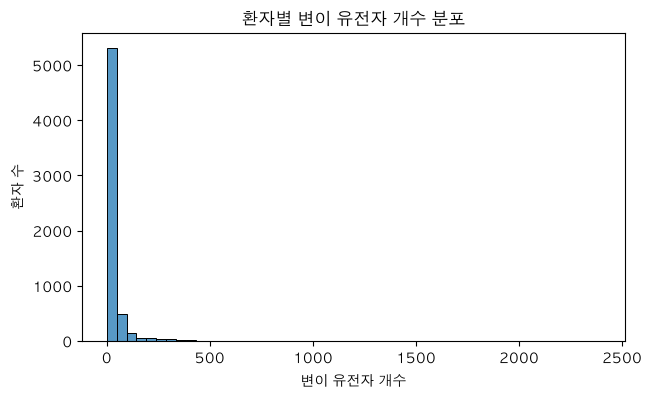

In [11]:
#  환자별 변이 개수 분포 (전체)

plt.figure(figsize=(7, 4))

sns.histplot(n_mut, bins=50)

plt.title("환자별 변이 유전자 개수 분포")
plt.xlabel("변이 유전자 개수")
plt.ylabel("환자 수")
plt.show()

⬆️ 그래프 해석
- 대부분의 환자는 변이 유전자 개수가 적은 구간에 집중되어 있으며, 오른쪽으로 긴 꼬리를 가진 분포를 보임.
- 평균 35.3개, 중앙값 14개, 최소 0개, 최대 2,393개로 일부 극단적으로 높은 값이 존재함. (describe() 참고)
- 극단값의 영향으로 평균이 중앙값보다 높게 나타남.

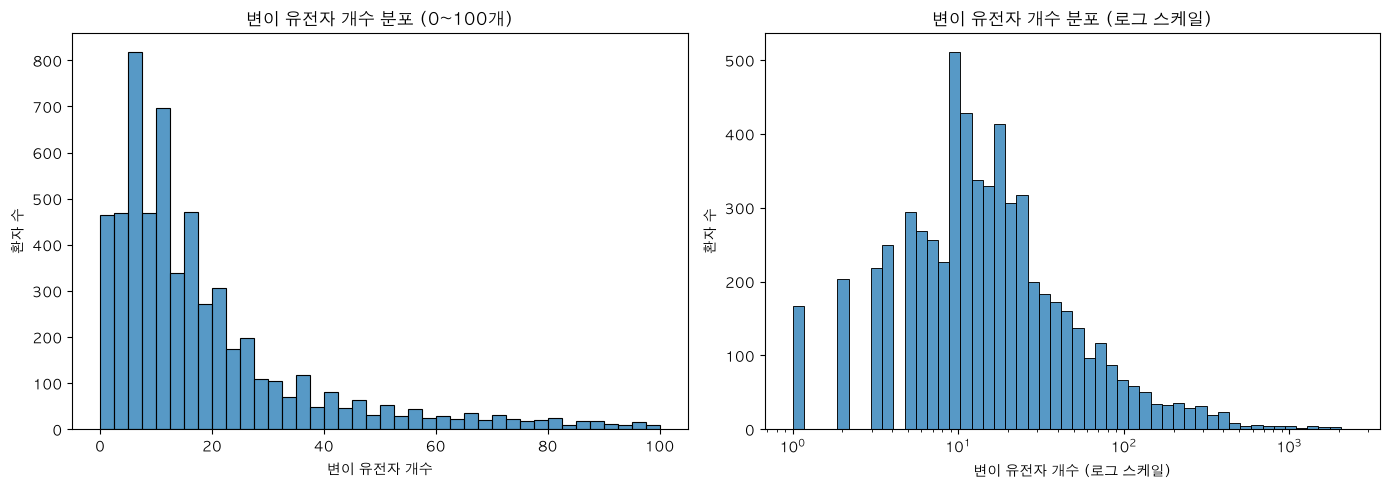

In [12]:
# 환자별 변이 유전자 개수 분포 비교 (0~100개 구간 / 로그 스케일)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. 변이 유전자 개수 100개 이하 구간 확대
sns.histplot(n_mut[n_mut <= 100], bins=40, ax=axes[0])

axes[0].set_title("변이 유전자 개수 분포 (0~100개)")
axes[0].set_xlabel("변이 유전자 개수")
axes[0].set_ylabel("환자 수")

# 2. 전체 분포 로그 스케일
sns.histplot(n_mut[n_mut > 0], bins=50, log_scale=(True, False), ax=axes[1])

axes[1].set_title("변이 유전자 개수 분포 (로그 스케일)")
axes[1].set_xlabel("변이 유전자 개수 (로그 스케일)")
axes[1].set_ylabel("환자 수")

plt.tight_layout()
plt.show()

In [13]:
print("변이 유전자 0개인 환자:", (n_mut == 0).sum(),"명")
print("변이 유전자 100개인 환자:", (n_mut > 100).sum(),"명")
print("변이 유전자 500개 환자:", (n_mut > 500).sum(),"명")

변이 유전자 0개인 환자: 94 명
변이 유전자 100개인 환자: 387 명
변이 유전자 500개 환자: 37 명


⬆️ 그래프 해석
- 0~100개 구간을 확대하면 변이 유전자 개수가 적은 환자가 다수이며, 개수가 증가할수록 환자 수가 감소하는 경향을 확인할 수 있음.
- 전체 6,201명 중 변이 유전자 100개 초과 환자는 387명(6.2%), 500개 초과 환자는 37명(0.6%)임.
- 로그 스케일에서도 소수 환자의 변이 유전자 개수가 매우 높은 긴 꼬리 분포가 확인됨.

### 2-3. 암 아형별 변이 특성 분석

In [14]:
# 변이 유전자 개수가 0인 환자 94명의 암 아형 분포

# 변이 유전자 개수가 0인 환자
zero_mut = train.loc[n_mut == 0]

# 암 아형별 환자 수
zero_counts = zero_mut["SUBCLASS"].value_counts()

print(zero_counts)

SUBCLASS
THYM      30
THCA      18
LAML      12
BRCA       5
KIPAN      4
PRAD       4
SARC       3
LGG        3
CESC       3
PCPG       3
LUSC       2
STES       2
GBMLGG     2
KIRC       2
PAAD       1
Name: count, dtype: int64


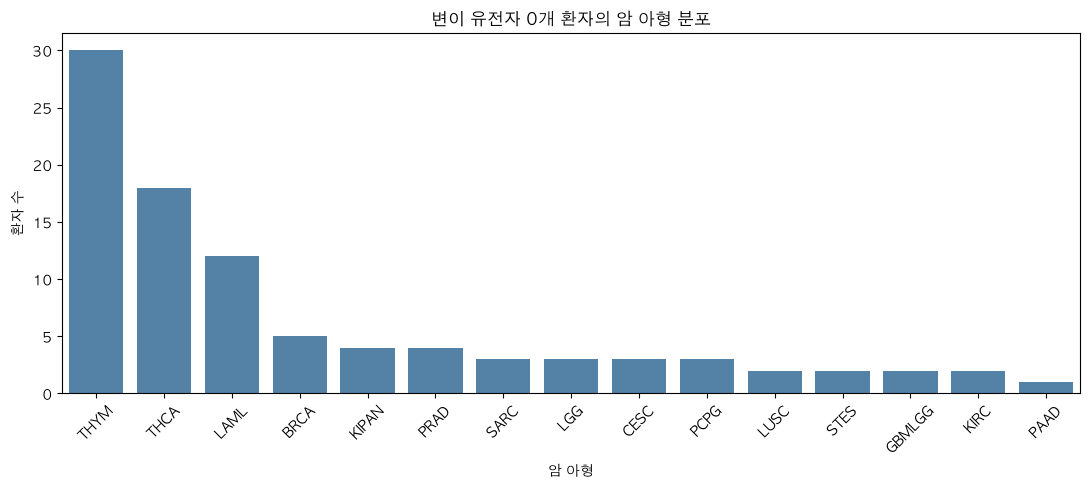

In [15]:
# 변이 유전자 개수가 0인 환자 94명의 암 아형 분포

plt.figure(figsize=(11, 5))

sns.barplot(
    x=zero_counts.index,
    y=zero_counts.values,
    color="steelblue"
)

plt.title("변이 유전자 0개 환자의 암 아형 분포")
plt.xlabel("암 아형")
plt.ylabel("환자 수")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

⬆️ 그래프 및 표 해석
- 변이 유전자 0개인 환자 총 94명(1.5%)중, THYM 30명, THCA 18명, LAML 12명 순으로 많음.
- 전체 암환자 6,201명 중 THYM 환자는 98명이며, 이 중 30명(30.6%)은 변이 유전자 개수가 0개로, 다른 주요 암 아형에 비해 높은 비율을 보임.
- 변이 유전자 개수가 암 아형 분류에 활용될 가능성이 있으나, 변이 정보가 없는 환자들은 구분이 어려울 수 있음.

In [16]:
# 암 아형별 변이 유전자 개수 요약 통계 (환자 수 내림차순)

eda_df = pd.DataFrame({
    "SUBCLASS": y_raw,
    "변이 유전자 수": n_mut
})

subclass_stats = (
    eda_df.groupby("SUBCLASS")["변이 유전자 수"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("count", ascending=False)
)

subclass_stats.columns = [
    "환자 수",
    "평균",
    "중앙값",
    "최솟값",
    "최댓값"
]

display(subclass_stats.round(2))

,환자 수,평균,중앙값,최솟값,최댓값
SUBCLASS,,,,,
BRCA,786,17.44,9.0,0,853
KIPAN,515,16.04,15.0,0,246
GBMLGG,461,12.54,11.0,0,121
STES,379,81.84,41.0,0,1076
KIRC,334,13.33,13.0,0,35
THCA,324,4.25,4.0,0,25
SKCM,276,132.53,85.5,3,2025
PRAD,266,7.70,6.0,0,205
OV,253,14.59,12.0,1,47


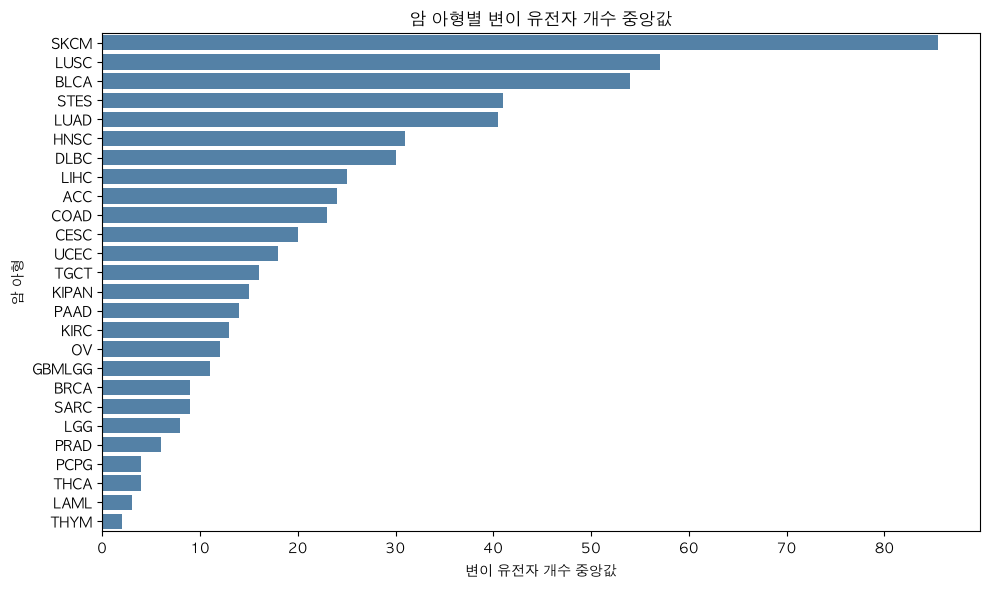

In [17]:
# 암 아형별 변이 유전자 개수 중앙값 비교

median_mut = subclass_stats["중앙값"].sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=median_mut.values,
    y=median_mut.index,
    color="steelblue"
)

plt.title("암 아형별 변이 유전자 개수 중앙값")
plt.xlabel("변이 유전자 개수 중앙값")
plt.ylabel("암 아형")

plt.tight_layout()
plt.show()

⬆️ 그래프 및 표 해석
- 암 아형에 따라 변이 유전자 개수 중앙값에 뚜렷한 차이가 나타남.
- SKCM(85.5개), LUSC(57개), BLCA(54개) 순으로 높았으며, THYM(2개), LAML(3개), THCA·PCPG(4개)에서 낮게 나타남.
- UCEC, PAAD, COAD 등은 평균과 중앙값의 차이가 커 일부 극단값이 평균에 영향을 미치는 것으로 판단됨.
- 따라서 변이 유전자 개수는 암 아형별 차이가 있지만, 같은 암 아형 내에서도 환자 간 편차가 클 수 있음.
- 변이 유전자 개수가 암 아형 분류에 유용한 파생변수로 활용될 가능성이 있음.

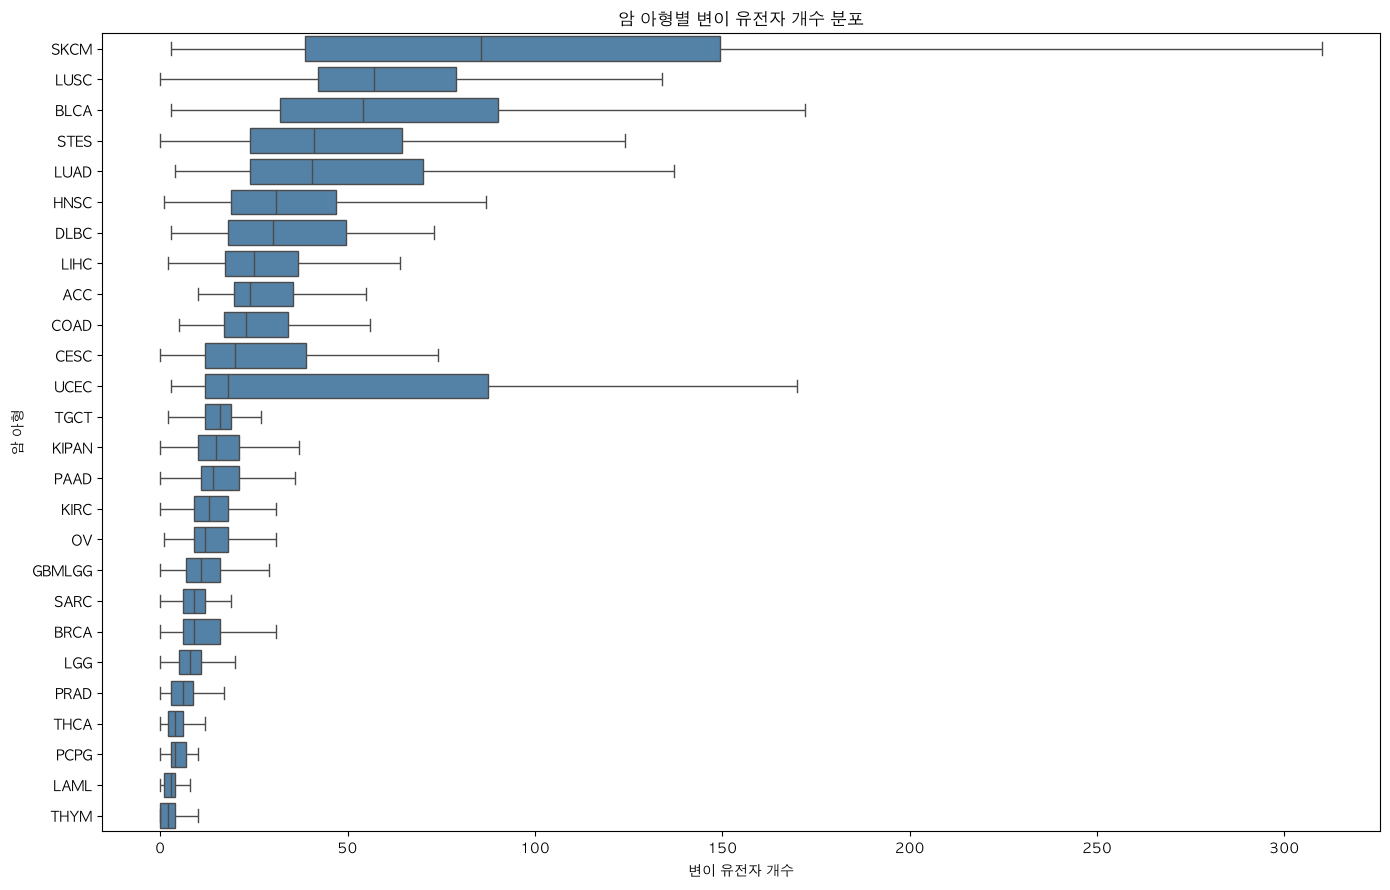

In [18]:
# 암 아형별 변이 유전자 개수 분포 비교 (박스플롯)

plt.figure(figsize=(14, 9))

# 중앙값이 높은 암 아형부터 정렬
order = (
    eda_df.groupby("SUBCLASS")["변이 유전자 수"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=eda_df,
    x="변이 유전자 수",
    y="SUBCLASS",
    order=order,
    showfliers=False,
    color="steelblue"
)

plt.title("암 아형별 변이 유전자 개수 분포")
plt.xlabel("변이 유전자 개수")
plt.ylabel("암 아형")

plt.tight_layout()
plt.show()

⬆️ 그래프 해석
- SKCM은 변이 유전자 개수 중앙값이 가장 높고, 환자 간 변이 개수의 편차도 크게 나타남.
- UCEC는 중앙값에 비해 분포 범위가 넓어 동일 암 아형 내에서도 변이 유전자 개수의 차이가 큼.
- THYM, LAML, THCA 등은 변이 유전자 개수가 적은 구간에 집중되어 있음.
- 암 아형 간 분포가 일부 겹치므로 변이 유전자 개수만으로 암 아형을 구분하는 데 한계가 있으나, 분류에 활용 가능한 파생변수로 판단됨.

### 2-4. 주요 변이 유전자 분석

In [19]:
# 유전자별 변이 발생 빈도 계산 (전체 학습 데이터)

print("⚠️주의⚠️ 변이 발생 횟수가 아니라 변이가 기록된 환자 수")

X_binary = binarize_mutations(X)

# 유전자별 변이가 기록된 환자 수
gene_mut_count = X_binary.sum(axis=0).sort_values(ascending=False)

# 유전자별 변이 발생 비율 (%)
gene_mut_rate = (gene_mut_count / len(X)) * 100

# 상위 20개 유전자 요약
top20_genes = pd.DataFrame({
    "변이 환자 수": gene_mut_count.head(20),
    "변이 발생 비율 (%)": gene_mut_rate.head(20)
})

display(top20_genes.round(2))

⚠️주의⚠️ 변이 발생 횟수가 아니라 변이가 기록된 환자 수


,변이 환자 수,변이 발생 비율 (%)
TP53,1770,28.54
PIK3CA,686,11.06
RYR2,643,10.37
SYNE1,642,10.35
PCLO,593,9.56
RYR1,473,7.63
SPTA1,461,7.43
KMT2D,451,7.27
IDH1,441,7.11
BRAF,438,7.06


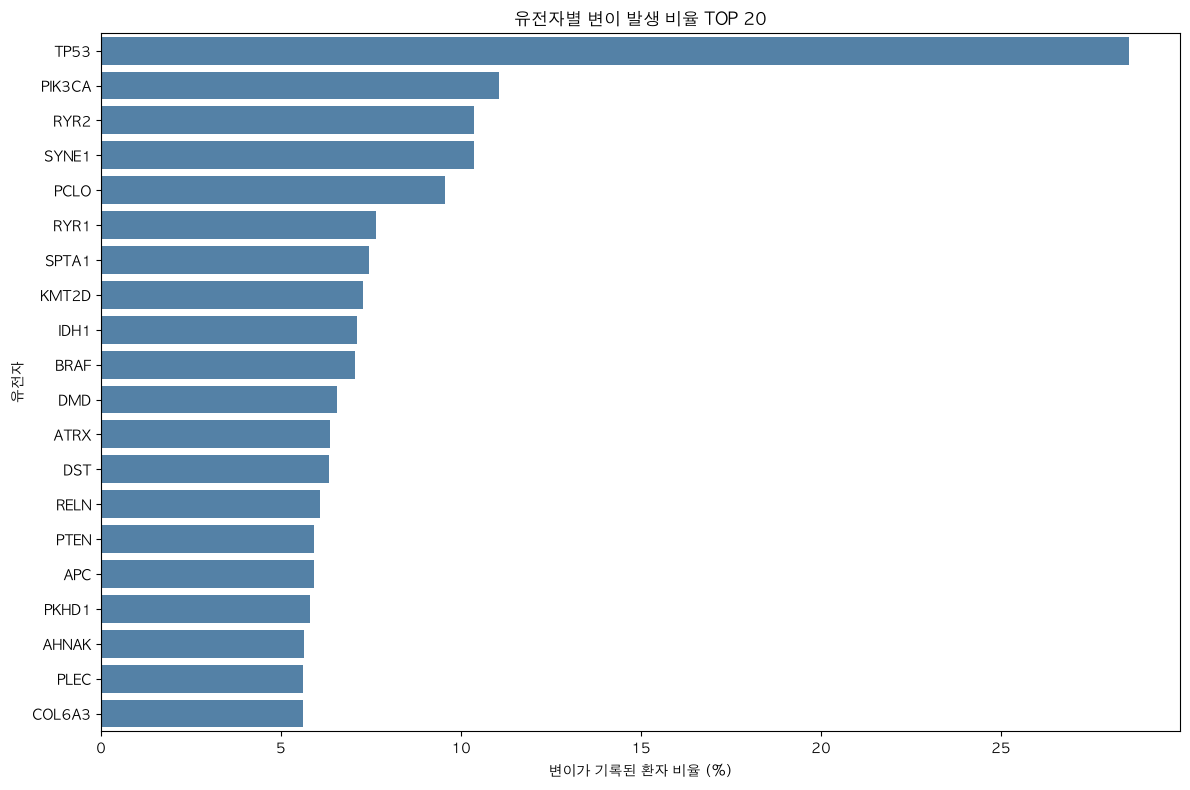

In [20]:
# 전체 환자에서 변이가 가장 자주 기록된 유전자 TOP 20

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top20_genes["변이 발생 비율 (%)"],
    y=top20_genes.index,
    color="steelblue"
)

plt.title("유전자별 변이 발생 비율 TOP 20")
plt.xlabel("변이가 기록된 환자 비율 (%)")
plt.ylabel("유전자")

plt.tight_layout()
plt.show()

⬆️ 그래프 및 표 해석
- TP53의 변이 발생 비율이 28.54%(1,770명)로 가장 높았으며, PIK3CA(11.06%), RYR2(10.37%), SYNE1(10.35%) 순으로 나타남.
- TP53은 두 번째로 높은 PIK3CA보다 약 2.6배 높은 변이 발생 비율을 보임 .
- 변이 발생 빈도가 높다고 반드시 암 아형 분류에 중요한 것은 아니므로, 암 아형별 변이 발생 비율을 추가로 비교할 필요가 있음.

### 2-5. 암 아형별 유전자 변이 특이성 분석

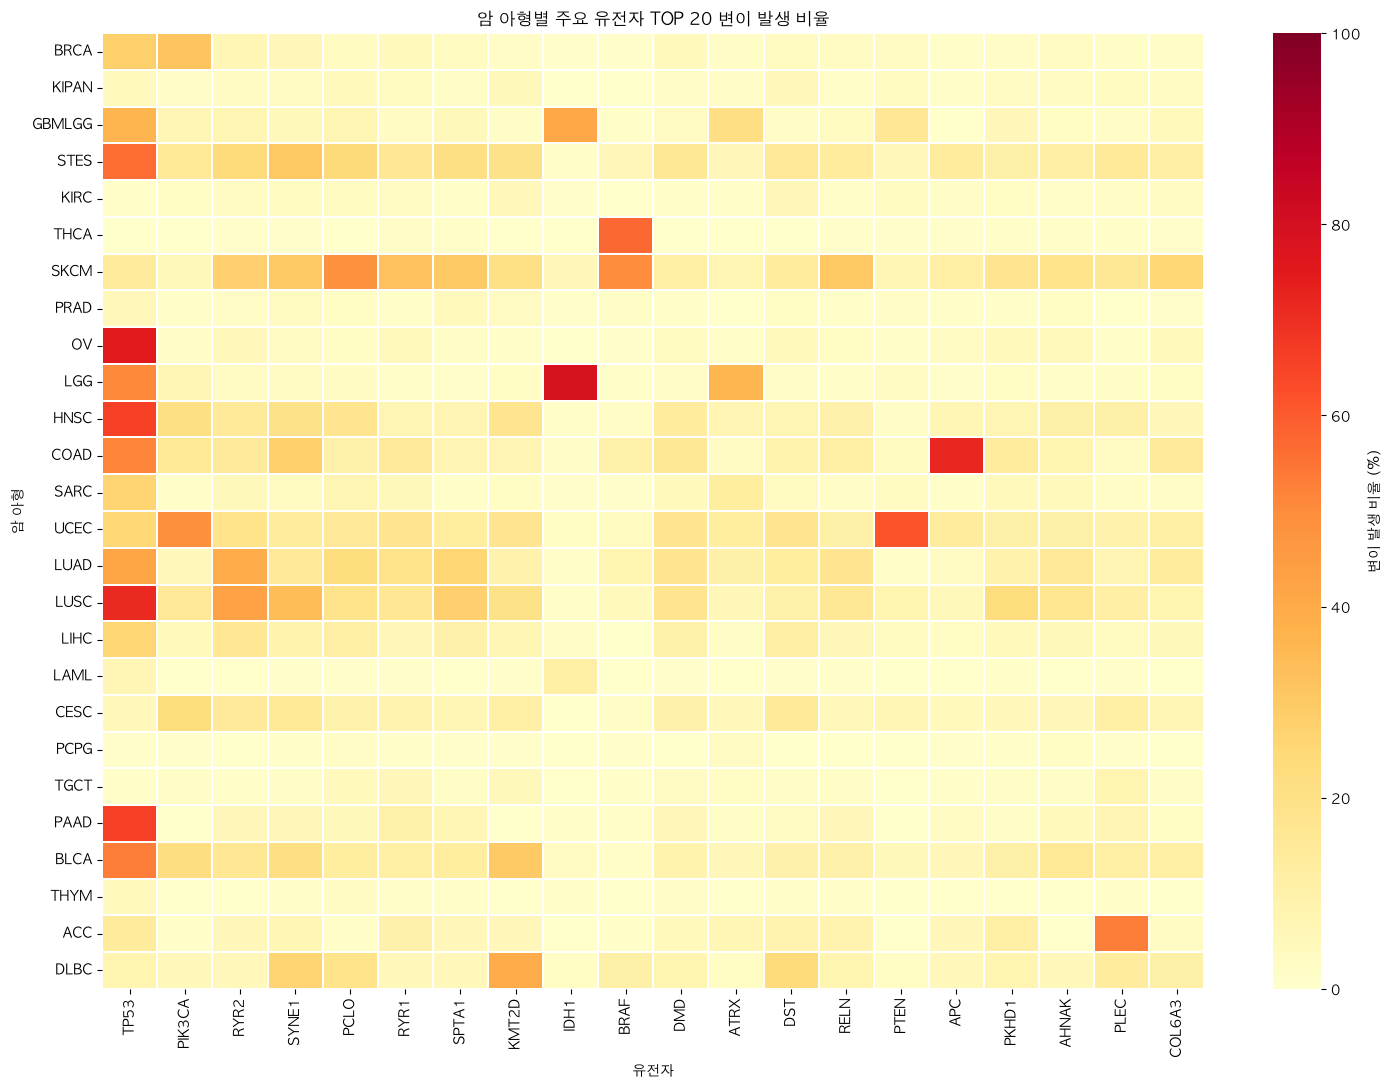

In [21]:
# 암 아형별 주요 유전자 TOP 20 변이 발생 비율 히트맵

top_genes = gene_mut_count.head(20).index

# TOP 20 유전자 변이 여부 + 암 아형
heatmap_df = X_binary[top_genes].copy()
heatmap_df["SUBCLASS"] = y_raw

# 암 아형별 변이 발생 비율 (%)
subclass_gene_rate = (
    heatmap_df.groupby("SUBCLASS")[top_genes]
    .mean() * 100
)

# 암 아형별 환자 수 내림차순 정렬
subclass_order = y_raw.value_counts().index
subclass_gene_rate = subclass_gene_rate.loc[subclass_order]

# 히트맵 시각화
plt.figure(figsize=(15, 11))

sns.heatmap(
    subclass_gene_rate,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "변이 발생 비율 (%)"}
)

plt.title("암 아형별 주요 유전자 TOP 20 변이 발생 비율")
plt.xlabel("유전자")
plt.ylabel("암 아형")

plt.tight_layout()
plt.show()

⬆️ 그래프 해석
- 주요 유전자 20개의 변이 발생 비율은 암 아형에 따라 서로 다른 패턴을 보임.
- IDH1은 LGG·GBMLGG, BRAF는 THCA·SKCM, APC는 COAD, PTEN은 UCEC에서 상대적으로 높은 변이 발생 비율을 보임.
- TP53은 여러 암 아형에서 높은 변이 발생 비율을 보여, 단일 유전자만으로 특정 암 아형을 구분하는 데 한계가 있을 수 있음.
- 암 아형별 유전자 변이 패턴이 다르게 나타나므로, 특정 유전자들의 변이 여부가 암 아형 분류에 유용할 가능성이 있음.

In [22]:
# 암 아형별 변이 발생 비율 TOP 5 유전자 (가로형 표)

# 암 아형별 전체 유전자 변이 발생 비율 계산
all_gene_rates = X_binary.groupby(y_raw).mean() * 100
all_gene_rates.index.name = "SUBCLASS"

# 암 아형별 TOP 5 유전자 추출
top5_by_subclass = (
    all_gene_rates
    .stack()
    .rename("변이 발생 비율 (%)")
    .reset_index()
    .rename(columns={"level_1": "유전자"})
    .sort_values(
        ["SUBCLASS", "변이 발생 비율 (%)"],
        ascending=[True, False]
    )
    .groupby("SUBCLASS")
    .head(5)
    .copy()
)

# 가로형 표로 변환
top5_by_subclass["순위"] = (
    top5_by_subclass.groupby("SUBCLASS").cumcount() + 1
)

top5_by_subclass["표시"] = (
    top5_by_subclass["유전자"]
    + " ("
    + top5_by_subclass["변이 발생 비율 (%)"].round(1).astype(str)
    + "%)"
)

top5_wide = top5_by_subclass.pivot(
    index="SUBCLASS",
    columns="순위",
    values="표시"
)

top5_wide.columns = [f"TOP {i}" for i in top5_wide.columns]

display(top5_wide)

,TOP 1,TOP 2,TOP 3,TOP 4,TOP 5
SUBCLASS,,,,,
ACC,PLEC (52.8%),LRIG1 (34.7%),SOWAHC (33.3%),CMPK2 (27.8%),NFKB2 (25.0%)
BLCA,TP53 (52.9%),KMT2D (29.8%),PIK3CA (22.1%),SYNE1 (21.2%),SPTAN1 (18.3%)
BRCA,PIK3CA (31.8%),TP53 (27.7%),CDH1 (9.3%),GATA3 (7.4%),MAP3K1 (7.1%)
CESC,PIK3CA (22.6%),SYNE1 (15.5%),DST (14.8%),RYR2 (14.2%),KMT2D (11.0%)
COAD,APC (71.7%),TP53 (51.6%),SYNE1 (27.8%),FBXW7 (16.6%),DMD (15.7%)
DLBC,KMT2D (39.5%),BTG2 (31.6%),BTG1 (26.3%),SYNE1 (26.3%),DST (23.7%)
GBMLGG,IDH1 (41.0%),TP53 (36.7%),ATRX (21.5%),PTEN (16.3%),EGFR (14.5%)
HNSC,TP53 (65.9%),CDKN2A (21.5%),PIK3CA (21.1%),SYNE1 (19.3%),NOTCH1 (18.8%)
KIPAN,VHL (29.9%),DST (5.2%),KMT2D (5.0%),MTOR (4.9%),PABPC1 (4.7%)


⬆️ 표 해석
- 암 아형별로 변이 발생 비율이 높은 유전자가 서로 다르게 나타남.
- LGG–IDH1(78.6%), COAD–APC(71.7%), UCEC–PTEN(61.6%), THCA–BRAF(57.4%) 등 특정 암 아형에서 높은 변이 비율을 보이는 유전자가 확인됨.
- VHL, NPM1, KIT 등 전체 변이 발생 빈도 TOP 20에 포함되지 않았던 유전자도 암 아형별 상위 유전자로 확인됨.
- 따라서 전체 변이 빈도뿐 아니라 암 아형 간 변이 발생 비율 차이를 고려한 추가 분석이 필요함.

In [23]:
# 암 아형별 변이율 차이 TOP 5 유전자 (가로형 표)

results = []

for subclass in y_raw.unique():
    mask = y_raw == subclass

    # 해당 암 아형과 나머지 암 아형의 변이율
    in_rate = X_binary.loc[mask].mean() * 100
    out_rate = X_binary.loc[~mask].mean() * 100

    # 변이율 차이
    diff = in_rate - out_rate

    temp = pd.DataFrame({
        "SUBCLASS": subclass,
        "유전자": X_binary.columns,
        "변이율 차이 (%p)": diff.values
    })

    results.append(temp)

gene_diff_df = pd.concat(results, ignore_index=True)

# 암 아형별 변이율 차이 TOP 5 추출
top5_diff = (
    gene_diff_df
    .sort_values(
        ["SUBCLASS", "변이율 차이 (%p)"],
        ascending=[True, False]
    )
    .groupby("SUBCLASS")
    .head(5)
    .copy()
)

# 가로형 표로 변환
top5_diff["순위"] = (
    top5_diff.groupby("SUBCLASS").cumcount() + 1
)

top5_diff["표시"] = (
    top5_diff["유전자"]
    + " ("
    + top5_diff["변이율 차이 (%p)"].round(1).astype(str)
    + "%p)"
)

top5_diff_wide = top5_diff.pivot(
    index="SUBCLASS",
    columns="순위",
    values="표시"
)

top5_diff_wide.columns = [f"TOP {i}" for i in top5_diff_wide.columns]

display(top5_diff_wide)

,TOP 1,TOP 2,TOP 3,TOP 4,TOP 5
SUBCLASS,,,,,
ACC,PLEC (47.7%p),LRIG1 (33.1%p),SOWAHC (33.0%p),CMPK2 (27.3%p),NFKB2 (24.2%p)
BLCA,TP53 (24.8%p),KMT2D (22.9%p),SPTAN1 (15.7%p),ERCC2 (15.3%p),CDKN1A (15.0%p)
BRCA,PIK3CA (23.8%p),CDH1 (7.8%p),GATA3 (6.1%p),MAP3K1 (5.4%p),RUNX1 (2.0%p)
CESC,PIK3CA (11.8%p),DST (8.7%p),PKD1 (7.1%p),HELZ2 (6.8%p),FBXW7 (6.1%p)
COAD,APC (68.3%p),TP53 (23.9%p),SYNE1 (18.1%p),FBXW7 (14.0%p),DMD (9.5%p)
DLBC,KMT2D (32.4%p),BTG2 (31.3%p),BTG1 (26.1%p),PIM1 (23.3%p),HLA-C (17.6%p)
GBMLGG,IDH1 (36.6%p),ATRX (16.3%p),EGFR (11.6%p),PTEN (11.2%p),TP53 (8.8%p)
HNSC,TP53 (38.8%p),CDKN2A (19.1%p),NOTCH1 (15.6%p),KMT2D (11.1%p),PIK3CA (10.4%p)
KIPAN,VHL (26.9%p),PABPC1 (3.5%p),MET (1.6%p),MAML2 (1.5%p),AQP7 (1.5%p)


⬆️ 표 해석
- 암 아형별 변이 발생 비율을 나머지 암 아형과 비교한 결과, LGG–IDH1(+74.2%p), COAD–APC(+68.3%p), UCEC–PTEN(+57.5%p) 등에서 큰 차이가 나타남.
- BRAF, IDH1, VHL 등은 여러 암 아형에서 높은 변이율 차이를 보여, 단일 유전자만으로 특정 암 아형을 구분하는 데 한계가 있을 수 있음.
- 특정 유전자의 변이 여부가 암 아형 분류에 유용할 가능성이 있으나, 실제 예측 기여도는 교차검증을 통해 확인해야 함.

### 2-6. 중복 및 유사도 행(Row) 확인

#### 중복 및 유사도 탐색

> **⚠️ 분석 결과 정정 안내**
>
> 초기 분석에서는 `ID` 컬럼이 유전자 피처에 포함되어 중복 및 유사도 계산에 영향을 주는 문제가 확인되었다.
>
> 따라서 아래 초기 분석에서 도출된 중복 건수, 유전자 차이 개수 및 변이 문자열 일치 여부는 유효한 최종 결과가 아니다.
>
> 오류 확인 이후 `gene_cols`에서 `ID`를 제외하고 재검증하였으며, **최종 해석에는 재검증 결과를 사용한다.**
>
> 초기 분석은 오류 발견 및 수정 과정을 기록하기 위해 유지하였다.

In [24]:
# 암종별 유전자 변이 패턴 완전 중복 확인

gene_cols = train.columns.drop("SUBCLASS")

# 타깃 제외, 유전자 정보가 완전히 동일한 행
dup_mask = train.duplicated(
    subset=gene_cols,
    keep=False
)

dup_summary = (
    train.assign(is_duplicate=dup_mask)
    .groupby("SUBCLASS")
    .agg(
        total_samples=("is_duplicate", "size"),
        duplicate_samples=("is_duplicate", "sum")
    )
)

dup_summary["duplicate_ratio"] = (
    dup_summary["duplicate_samples"]
    / dup_summary["total_samples"]
)

dup_summary.sort_values(
    "duplicate_ratio",
    ascending=False
)

,total_samples,duplicate_samples,duplicate_ratio
SUBCLASS,,,
ACC,72,0,0.0
BLCA,104,0,0.0
THYM,98,0,0.0
THCA,324,0,0.0
TGCT,124,0,0.0
STES,379,0,0.0
SKCM,276,0,0.0
SARC,198,0,0.0
PRAD,266,0,0.0


In [25]:
# 신장암 샘플 간 유사도 확인

import numpy as np
from sklearn.metrics import pairwise_distances

# 신장암 계열 샘플만 추출
kidney = train[
    train["SUBCLASS"].isin(["KIRC", "KIPAN"])
].copy()

# 유전자 컬럼만 사용
gene_cols = train.columns.drop("SUBCLASS")

# WT, 결측치는 0 / 변이가 있으면 1
X_kidney = (
    kidney[gene_cols].notna()
    & kidney[gene_cols].ne("WT")
).to_numpy(dtype=bool)

# Jaccard 유사도 계산
similarity = 1 - pairwise_distances(
    X_kidney,
    metric="jaccard"
)

# 자기 자신과의 비교 제외
np.fill_diagonal(similarity, np.nan)

# 유사도별 샘플 쌍 개수
upper = similarity[np.triu_indices_from(similarity, k=1)]

for threshold in [0.9, 0.95, 0.99, 1.0]:
    print(
        f"유사도 {threshold:.0%} 이상: "
        f"{np.sum(upper >= threshold):,}쌍"
    )

유사도 90% 이상: 974쌍
유사도 95% 이상: 974쌍
유사도 99% 이상: 974쌍
유사도 100% 이상: 974쌍


⬆️ 해석 [정정 전 결과] ID 컬럼이 포함된 상태에서 계산한 결과이며, 최종 결론으로 사용하지 않음.
- 신장암 계열에서 변이가 발생한 유전자 집합이 완전히 같은 샘플 쌍이 974개 존재함.
- 90%, 95%, 99%, 100% 결과가 전부 974쌍으로 동일 -> 90~100% 사이의 유사도는 없고 정확히 100%인 쌍만 있다는 의미임. (변이 유전자가 매우 적은 희소 데이터에서 나타날 수 있음)

In [26]:
# 974쌍의 변이 개수 확인

# 유사도 100%인 샘플 쌍 추출
i, j = np.where(np.triu(similarity == 1.0, k=1))

# 각 샘플의 변이 유전자 수
mutation_counts = X_kidney.sum(axis=1)

# 유사도 100%인 쌍의 변이 개수 분포
import pandas as pd

pair_summary = pd.DataFrame({
    "mutation_count": mutation_counts[i],
    "pair_count": 1
})

print("유사도 100%인 쌍의 변이 유전자 수 분포")
print(
    pair_summary.groupby("mutation_count")["pair_count"]
    .sum()
    .sort_index()
)

print("\n유사도 100%인 쌍의 암종 조합")
subclasses = kidney["SUBCLASS"].to_numpy()

pair_types = pd.Series([
    " / ".join(sorted([subclasses[a], subclasses[b]]))
    for a, b in zip(i, j)
])

print(pair_types.value_counts())

유사도 100%인 쌍의 변이 유전자 수 분포
mutation_count
1      15
2     703
3       2
4       1
5       5
6      11
7      10
8       9
9       5
10     20
11     21
12     15
13     19
14     18
15      6
16     19
17      6
18     13
19     12
20     11
21      8
22      9
23      7
24      6
25      9
26      1
27      5
28      1
29      2
31      1
32      2
36      2
Name: pair_count, dtype: int64

유사도 100%인 쌍의 암종 조합
KIPAN / KIRC     624
KIPAN / KIPAN    196
KIRC / KIRC      154
Name: count, dtype: int64


⬆️ 해석 [정정 전 결과] ID 컬럼이 포함된 상태에서 계산한 결과이며, 최종 결론으로 사용하지 않음.
- 703쌍은 변이 유전자가 2개임. 적은 수의 변이 유전자가 일치해서 유사도가 높게 나온 경우일 수 있음.
- KIRC–KIPAN 조합이 624쌍(약 64.1%)**이야. 서로 다른 라벨을 가진 샘플 사이에서 같은 변이 유전자 집합이 상당수 발견됨.
- 자료 조사 시, KIPAN이 KIRC를 포함하는 상위 코호트이며 현재 데이터셋에선 KIRC와 KIPAN이 서로 다른 SUBCLASS 라벨로 존재히고 있는 상태임.

In [27]:
# 변이 유전자 집합이 100% 일치한 974쌍의
# 실제 변이 문자열 일치 여부 확인

rows = []

for a, b in zip(i, j):
    row_a = kidney.iloc[a][gene_cols]
    row_b = kidney.iloc[b][gene_cols]

    # 실제 변이가 존재하는 유전자만 비교
    mutated = (
        row_a.notna()
        & row_a.ne("WT")
    )

    exact_match = row_a[mutated].equals(row_b[mutated])

    rows.append({
        "sample_a": kidney.index[a],
        "sample_b": kidney.index[b],
        "class_a": kidney.iloc[a]["SUBCLASS"],
        "class_b": kidney.iloc[b]["SUBCLASS"],
        "mutation_count": int(mutated.sum()),
        "exact_match": exact_match
    })

exact_pairs = pd.DataFrame(rows)

print("실제 변이 문자열 일치 여부")
print(exact_pairs["exact_match"].value_counts())

print("\n변이 문자열까지 동일한 쌍의 암종 조합")
print(
    exact_pairs[exact_pairs["exact_match"]]
    .groupby(["class_a", "class_b"])
    .size()
)

print("\n변이 문자열까지 동일한 쌍 중 변이 10개 이상")
print(
    exact_pairs[
        exact_pairs["exact_match"]
        & (exact_pairs["mutation_count"] >= 10)
    ].shape[0]
)

실제 변이 문자열 일치 여부
exact_match
False    974
Name: count, dtype: int64

변이 문자열까지 동일한 쌍의 암종 조합
Series([], dtype: int64)

변이 문자열까지 동일한 쌍 중 변이 10개 이상
0


⬆️ 해석 [정정 전 결과] ID 컬럼이 포함된 상태에서 계산한 결과이며, 최종 결론으로 사용하지 않음.
- 같은 유전자들에서 변이가 발생한 샘플은 존재함.
- 하지만 그 974쌍 중 실제 변이 문자열까지 모두 동일한 쌍은 없음.
- 따라서 현재 검사한 974쌍은 완전히 동일한 변이 프로필을 가진 샘플은 아님.

In [28]:
rows = []

for a, b in zip(i, j):
    row_a = kidney.iloc[a][gene_cols]
    row_b = kidney.iloc[b][gene_cols]

    # 변이가 존재하는 유전자
    mutated = row_a.notna() & row_a.ne("WT")

    # 변이 문자열이 동일한 유전자 수
    match_count = (row_a[mutated] == row_b[mutated]).sum()

    mutation_count = mutated.sum()

    rows.append({
        "class_a": kidney.iloc[a]["SUBCLASS"],
        "class_b": kidney.iloc[b]["SUBCLASS"],
        "mutation_count": mutation_count,
        "match_count": match_count,
        "match_ratio": match_count / mutation_count
    })

match_df = pd.DataFrame(rows)

print("변이 문자열 일치율 분포")
print(match_df["match_ratio"].describe())

print("\n일치율 80% 이상인 쌍")
print((match_df["match_ratio"] >= 0.8).sum())

print("\n일치율 90% 이상인 쌍")
print((match_df["match_ratio"] >= 0.9).sum())

print("\n변이 10개 이상이면서 일치율 80% 이상인 쌍")
print(
    match_df[
        (match_df["mutation_count"] >= 10)
        & (match_df["match_ratio"] >= 0.8)
    ].shape[0]
)

변이 문자열 일치율 분포
count    974.000000
mean       0.253806
std        0.405340
min        0.000000
25%        0.000000
50%        0.000000
75%        0.833333
max        0.972222
Name: match_ratio, dtype: float64

일치율 80% 이상인 쌍
253

일치율 90% 이상인 쌍
213

변이 10개 이상이면서 일치율 80% 이상인 쌍
213


In [29]:
# 213쌍이 어떤 암종 조합인지 확인

# 변이 10개 이상 + 문자열 일치율 80% 이상
high_sim = match_df[
    (match_df["mutation_count"] >= 10)
    & (match_df["match_ratio"] >= 0.8)
].copy()

# 암종 조합별 집계
high_sim["class_pair"] = high_sim.apply(
    lambda row: " / ".join(
        sorted([row["class_a"], row["class_b"]])
    ),
    axis=1
)

print("고유사도 샘플 쌍의 암종 조합")
print(high_sim["class_pair"].value_counts())

print("\n일치율 상위 10쌍")
display(
    high_sim.sort_values(
        ["match_ratio", "mutation_count"],
        ascending=False
    ).head(10)
)

고유사도 샘플 쌍의 암종 조합
class_pair
KIPAN / KIRC    213
Name: count, dtype: int64

일치율 상위 10쌍


,class_a,class_b,mutation_count,match_count,match_ratio,class_pair
99,KIPAN,KIRC,36,35,0.972222,KIPAN / KIRC
888,KIPAN,KIRC,36,35,0.972222,KIPAN / KIRC
533,KIRC,KIPAN,32,31,0.968750,KIPAN / KIRC
809,KIRC,KIPAN,32,31,0.968750,KIPAN / KIRC
422,KIRC,KIPAN,31,30,0.967742,KIPAN / KIRC
709,KIPAN,KIRC,29,28,0.965517,KIPAN / KIRC
779,KIPAN,KIRC,29,28,0.965517,KIPAN / KIRC
85,KIPAN,KIRC,28,27,0.964286,KIPAN / KIRC
262,KIPAN,KIRC,27,26,0.962963,KIPAN / KIRC
454,KIPAN,KIRC,27,26,0.962963,KIPAN / KIRC


In [30]:
#  고유 샘플 수 확인

# 기존 974쌍에서 고유사도 213쌍의 실제 샘플 위치 추출
selected = (
    (match_df["mutation_count"] >= 10)
    & (match_df["match_ratio"] >= 0.8)
).to_numpy()

high_i = i[selected]
high_j = j[selected]

# 중복 없이 등장한 샘플 위치
unique_positions = np.unique(
    np.concatenate([high_i, high_j])
)

print("고유사도 샘플 쌍:", len(high_i))
print("실제 고유 샘플 수:", len(unique_positions))

print("\n암종별 고유 샘플 수")
print(
    kidney.iloc[unique_positions]["SUBCLASS"]
    .value_counts()
)

print("\n고유사도 쌍에 가장 많이 등장한 샘플")
pair_counts = pd.Series(
    np.concatenate([high_i, high_j])
).value_counts()

print(pair_counts.head(10))

고유사도 샘플 쌍: 213
실제 고유 샘플 수: 426

암종별 고유 샘플 수
SUBCLASS
KIRC     213
KIPAN    213
Name: count, dtype: int64

고유사도 쌍에 가장 많이 등장한 샘플
5     1
6     1
7     1
9     1
20    1
25    1
28    1
31    1
33    1
34    1
Name: count, dtype: int64


In [31]:
# 고유사도 213쌍의 일치율 분포 확인
high_matches = match_df.loc[selected].copy()

print("일치율 통계")
print(high_matches["match_ratio"].describe())

print("\n100% 일치하는 쌍:")
print((high_matches["match_ratio"] == 1.0).sum())

print("\n일치율별 쌍 개수")
print(
    pd.cut(
        high_matches["match_ratio"],
        bins=[0.8, 0.9, 0.95, 0.99, 1.0],
        include_lowest=True
    ).value_counts().sort_index()
)

일치율 통계
count    213.000000
mean       0.934584
std        0.019944
min        0.900000
25%        0.916667
50%        0.937500
75%        0.950000
max        0.972222
Name: match_ratio, dtype: float64

100% 일치하는 쌍:
0

일치율별 쌍 개수
match_ratio
(0.799, 0.9]     20
(0.9, 0.95]     140
(0.95, 0.99]     53
(0.99, 1.0]       0
Name: count, dtype: int64


⬆️ 해석 [정정 전 결과] ID 컬럼이 포함된 상태에서 계산한 결과이며, 최종 결론으로 사용하지 않음.
- 213개의 KIRC–KIPAN 쌍이 높은 변이 일치율을 보임.
- 각 샘플은 한 쌍에만 등장함.
- 완전히 일치하는 쌍은 없음.

In [32]:
# 양쪽 샘플의 변이를 모두 고려하기

rows_symmetric = []

for a, b in zip(i, j):
    row_a = kidney.iloc[a][gene_cols]
    row_b = kidney.iloc[b][gene_cols]

    mutated_a = row_a.notna() & row_a.ne("WT")
    mutated_b = row_b.notna() & row_b.ne("WT")

    # 두 샘플 중 하나라도 변이가 있는 유전자
    mutated_union = mutated_a | mutated_b

    # 양쪽 모두 변이가 있고 문자열까지 같은 경우
    exact_match = (
        mutated_a
        & mutated_b
        & row_a.eq(row_b)
    )

    union_count = int(mutated_union.sum())
    match_count = int(exact_match.sum())

    rows_symmetric.append({
        "class_a": kidney.iloc[a]["SUBCLASS"],
        "class_b": kidney.iloc[b]["SUBCLASS"],
        "union_count": union_count,
        "match_count": match_count,
        "match_ratio": (
            match_count / union_count
            if union_count > 0 else np.nan
        )
    })

match_df_symmetric = pd.DataFrame(rows_symmetric)

print("대칭적 변이 일치율 분포")
print(match_df_symmetric["match_ratio"].describe())

print("\n변이 유전자 10개 이상 + 일치율 80% 이상")
print(
    (
        (match_df_symmetric["union_count"] >= 10)
        & (match_df_symmetric["match_ratio"] >= 0.8)
    ).sum()
)

대칭적 변이 일치율 분포
count    974.000000
mean       0.253806
std        0.405340
min        0.000000
25%        0.000000
50%        0.000000
75%        0.833333
max        0.972222
Name: match_ratio, dtype: float64

변이 유전자 10개 이상 + 일치율 80% 이상
213


In [33]:
# 정말 동일한 213쌍인지 검증

# 기존 방식에서 선택된 쌍
old_selected = (
    (match_df["mutation_count"] >= 10)
    & (match_df["match_ratio"] >= 0.8)
).to_numpy()

# 대칭적 방식에서 선택된 쌍
new_selected = (
    (match_df_symmetric["union_count"] >= 10)
    & (match_df_symmetric["match_ratio"] >= 0.8)
).to_numpy()

print("기존 고유사도 쌍:", old_selected.sum())
print("새로운 고유사도 쌍:", new_selected.sum())

print("\n두 방식에서 공통으로 선택된 쌍:")
print((old_selected & new_selected).sum())

print("\n기존 방식에서만 선택된 쌍:")
print((old_selected & ~new_selected).sum())

print("\n새로운 방식에서만 선택된 쌍:")
print((~old_selected & new_selected).sum())

기존 고유사도 쌍: 213
새로운 고유사도 쌍: 213

두 방식에서 공통으로 선택된 쌍:
213

기존 방식에서만 선택된 쌍:
0

새로운 방식에서만 선택된 쌍:
0


In [34]:
# 213쌍의 변이 개수와 일치율 확인

high_sym = match_df_symmetric.loc[new_selected].copy()

print("고유사도 213쌍의 변이 개수 및 일치율")
display(
    high_sym[
        ["union_count", "match_count", "match_ratio"]
    ].describe().round(3)
)

print("\n변이 개수별 쌍 분포")
print(
    pd.cut(
        high_sym["union_count"],
        bins=[0, 10, 20, 50, 100, float("inf")],
        labels=["1~10", "11~20", "21~50", "51~100", "101+"]
    ).value_counts().sort_index()
)

고유사도 213쌍의 변이 개수 및 일치율


,union_count,match_count,match_ratio
count,213.000,213.000,213.000
mean,16.892,15.892,0.935
std,5.584,5.584,0.020
min,10.000,9.000,0.900
25%,12.000,11.000,0.917
50%,16.000,15.000,0.938
75%,20.000,19.000,0.950
max,36.000,35.000,0.972



변이 개수별 쌍 분포
union_count
1~10       20
11~20     140
21~50      53
51~100      0
101+        0
Name: count, dtype: int64


⬆️ 해석 [정정 전 결과] ID 컬럼이 포함된 상태에서 계산한 결과이며, 최종 결론으로 사용하지 않음.
- 모든 쌍에서 union_count - match_count = 1로 확인돰.
- 즉, 213쌍이 변이 문자열 하나만 다르고 나머지는 모두 동일한 구조일 가능성이 매우 높음.

In [35]:
# 불일치 유전자 확인

from collections import Counter

# 고유사도 213쌍의 실제 샘플 위치
high_i = i[new_selected]
high_j = j[new_selected]

diff_counts = []
diff_genes = Counter()

for a, b in zip(high_i, high_j):
    row_a = kidney.iloc[a][gene_cols]
    row_b = kidney.iloc[b][gene_cols]

    mutated_a = row_a.notna() & row_a.ne("WT")
    mutated_b = row_b.notna() & row_b.ne("WT")

    union = mutated_a | mutated_b

    # 양쪽 중 변이가 하나라도 있고, 정확히 일치하지 않는 유전자
    same = mutated_a & mutated_b & row_a.eq(row_b)
    different = union & ~same

    diff_counts.append(int(different.sum()))
    diff_genes.update(different.index[different].tolist())

print("쌍별 불일치 유전자 개수")
print(pd.Series(diff_counts).value_counts().sort_index())

print("\n가장 자주 불일치하는 유전자 TOP 20")
print(pd.Series(diff_genes).sort_values(ascending=False).head(20))

쌍별 불일치 유전자 개수
1    213
Name: count, dtype: int64

가장 자주 불일치하는 유전자 TOP 20
ID    213
dtype: int64


⬆️ 해석
- 213쌍 모두 ID만 다르고 나머지 비교 대상 컬럼은 동일함.
- 사용한 gene_cols에 ID가 포함되어 있었던 것으로 확인되어 지금까지 계산한 변이 개수와 일치율은 잘못된 컬럼 구성의 영향을 받음.
- gene_cols에서 ID 제거 후 재검증 진행 필요함.

> **⚠️ 분석 결과 정정 안내**
>
> 오류 확인 이후 `gene_cols`에서 `ID`를 제외하고 재검증하였으며, **최종 해석에는 아래 재검증 결과를 사용한다.**


In [36]:
# gene_cols에서 ID 제거 후 재검증

# 실제 유전자 컬럼만 선택
gene_cols_clean = [
    col for col in gene_cols
    if col not in ["ID", "SUBCLASS"]
]

print("기존 컬럼 수:", len(gene_cols))
print("수정 후 컬럼 수:", len(gene_cols_clean))

# 기존 213쌍의 실제 유전자 변이 비교
results = []

for a, b in zip(high_i, high_j):
    row_a = kidney.iloc[a][gene_cols_clean]
    row_b = kidney.iloc[b][gene_cols_clean]

    mutated_a = row_a.notna() & row_a.ne("WT")
    mutated_b = row_b.notna() & row_b.ne("WT")

    union = mutated_a | mutated_b
    same = mutated_a & mutated_b & row_a.eq(row_b)

    results.append({
        "union_count": int(union.sum()),
        "match_count": int(same.sum()),
        "diff_count": int((union & ~same).sum())
    })

results_df = pd.DataFrame(results)

print("\nID 제외 후 불일치 유전자 개수")
print(results_df["diff_count"].value_counts().sort_index())

print("\n실제 변이 유전자 개수")
print(results_df["union_count"].describe())

기존 컬럼 수: 4385
수정 후 컬럼 수: 4384

ID 제외 후 불일치 유전자 개수
diff_count
0    213
Name: count, dtype: int64

실제 변이 유전자 개수
count    213.000000
mean      15.892019
std        5.584056
min        9.000000
25%       11.000000
50%       15.000000
75%       19.000000
max       35.000000
Name: union_count, dtype: float64


⬆️ 해석
- 분석한 213쌍은 ID를 제외한 4,384개 유전자 컬럼에서 변이 패턴이 완전히 동일함.
- 단, 두 샘플이 같은 환자라는 뜻은 아니며, 관측된 유전자 데이터가 동일하다는 뜻임.
- 동일한 입력 유전자 패턴에 서로 다른 정답 레이블이 붙어 있다면, 유전체 변이만 사용하는 분류 모델에는 구분할 수 없는 사례가 존재하며, 이러한 사례는 모델 성능의 한계 요인이 될 수 있음.

In [37]:
# 전체 데이터에서 중복 변이 패턴 확인

# 유전자 변이 패턴 기준 그룹 생성 (ID, SUBCLASS 제외)
gene_cols_all = train.columns.drop(["ID", "SUBCLASS"])

# 동일 변이 패턴을 가진 샘플 그룹 식별
pattern_id = pd.util.hash_pandas_object(
    train[gene_cols_all],
    index=False
)

pattern_summary = (
    pd.DataFrame({
        "pattern_id": pattern_id.to_numpy(),
        "SUBCLASS": train["SUBCLASS"].to_numpy()
    })
    .groupby("pattern_id")
    .agg(
        sample_count=("SUBCLASS", "size"),
        class_count=("SUBCLASS", "nunique")
    )
)

conflicting_patterns = pattern_summary[
    pattern_summary["class_count"] > 1
]

print("전체 고유 변이 패턴 수:", len(pattern_summary))
print("서로 다른 암종 레이블을 가진 동일 변이 패턴 수:", len(conflicting_patterns))
print("해당 패턴에 포함된 전체 샘플 수:", conflicting_patterns["sample_count"].sum())

전체 고유 변이 패턴 수: 5636
서로 다른 암종 레이블을 가진 동일 변이 패턴 수: 447
해당 패턴에 포함된 전체 샘플 수: 1005


⬆️ 해석
- 전체 학습 샘플의 약 16.2%는 동일한 입력 변이 패턴에 서로 다른 정답 레이블이 존재하는 그룹에 속해 있음.

In [38]:
# 서로 다른 암종 레이블을 가진 동일 변이 패턴의 암종 조합 분석

pattern_classes = pd.DataFrame({
    "pattern_id": pattern_id.to_numpy(),
    "SUBCLASS": train["SUBCLASS"].to_numpy()
})

conflict_ids = conflicting_patterns.index

conflict_data = pattern_classes[
    pattern_classes["pattern_id"].isin(conflict_ids)
]

# 각 패턴에 포함된 암종 조합
class_combinations = (
    conflict_data.groupby("pattern_id")["SUBCLASS"]
    .apply(lambda x: " / ".join(sorted(x.unique())))
)

print("레이블 충돌 암종 조합 TOP 20")
print(class_combinations.value_counts().head(20))

print("\n충돌 패턴당 암종 종류 수")
print(
    conflicting_patterns["class_count"]
    .value_counts()
    .sort_index()
)

print("\n충돌 패턴당 샘플 수")
print(
    conflicting_patterns["sample_count"]
    .value_counts()
    .sort_index()
)

레이블 충돌 암종 조합 TOP 20
SUBCLASS
KIPAN / KIRC                                                                                                272
GBMLGG / LGG                                                                                                173
BRCA / CESC / GBMLGG / KIPAN / KIRC / LAML / LGG / LUSC / PAAD / PCPG / PRAD / SARC / STES / THCA / THYM      1
LGG / THCA                                                                                                    1
Name: count, dtype: int64

충돌 패턴당 암종 종류 수
class_count
2     446
15      1
Name: count, dtype: int64

충돌 패턴당 샘플 수
sample_count
2     443
3       1
4       1
18      1
94      1
Name: count, dtype: int64


⬆️ 해석
- KIRC–KIPAN 처럼 LGG와 GBMLGG는 상위 개념과 하위개념임.
- 447개 중 445개(99.6%)가 두 암종 조합에 집중되어 있음.
- KIRC / KIPAN: 신장암 관련 레이블
- GBMLGG / LGG: 뇌종양 관련 레이블

In [39]:
# 대규모 충돌 패턴의 정체 확인

# 샘플 수가 많은 충돌 패턴 확인
large_patterns = conflicting_patterns[
    conflicting_patterns["sample_count"] >= 10
]

for pid, info in large_patterns.iterrows():
    subset = pattern_classes[
        pattern_classes["pattern_id"] == pid
    ]

    # 해당 패턴의 대표 샘플
    sample_idx = subset.index[0]
    sample = train.loc[sample_idx, gene_cols_all]

    mutated = sample.notna() & sample.ne("WT")

    print("=" * 50)
    print("샘플 수:", info["sample_count"])
    print("암종 수:", info["class_count"])
    print("\n암종별 샘플 수:")
    print(subset["SUBCLASS"].value_counts())
    print("\n변이 유전자 수:", mutated.sum())
    print("\n변이 유전자 예시:")
    print(sample[mutated].head(10))

샘플 수: 94
암종 수: 15

암종별 샘플 수:
SUBCLASS
THYM      30
THCA      18
LAML      12
BRCA       5
KIPAN      4
PRAD       4
SARC       3
LGG        3
CESC       3
PCPG       3
LUSC       2
STES       2
GBMLGG     2
KIRC       2
PAAD       1
Name: count, dtype: int64

변이 유전자 수: 0

변이 유전자 예시:
Series([], Name: 66, dtype: str)
샘플 수: 18
암종 수: 2

암종별 샘플 수:
SUBCLASS
THCA    17
LGG      1
Name: count, dtype: int64

변이 유전자 수: 1

변이 유전자 예시:
BRAF    V600E
Name: 811, dtype: str


⬆️ 해석
- KIRC–KIPAN: 272개
- GBMLGG–LGG: 173개
- LGG–THCA: 1개
- 15개 암종 혼합: 1개
- KIRC–KIPAN과 GBMLGG–LGG의 충돌은 레이블 체계가 겹치는 문제일 가능성이 있고, 나머지 두 패턴은 입력 유전체 정보만으로 암종을 구분하기 어려운 사례일 수 있음.

In [40]:
# 실제 모델에 얼마나 큰 영향을 줄 수 있는지 계산

# 동일한 변이 패턴별 가장 빈도가 높은 암종 수
pattern_label_counts = (
    pattern_classes
    .groupby(["pattern_id", "SUBCLASS"])
    .size()
)

majority_counts = (
    pattern_label_counts
    .groupby(level="pattern_id")
    .max()
)

# 동일 입력에 동일 예측을 하는 분류기의 최소 오류 수
minimum_errors = (
    pattern_summary["sample_count"] - majority_counts
).sum()

print("전체 학습 샘플 수:", len(train))
print("이론적 최소 오분류 샘플 수:", minimum_errors)
print("전체 대비 최소 오류율:", round(minimum_errors / len(train) * 100, 2), "%")
print("이론적 최대 학습 정확도:", round((1 - minimum_errors / len(train)) * 100, 2), "%")

전체 학습 샘플 수: 6201
이론적 최소 오분류 샘플 수: 511
전체 대비 최소 오류율: 8.24 %
이론적 최대 학습 정확도: 91.76 %


해석 ⬆️
- 레이블 충돌: 전체 6,201개 샘플 중 1,005개(16.2%)가 동일한 유전체 변이 패턴에 서로 다른 암종 레이블을 가짐.
- 이론적 최소 오분류: 동일한 입력에 동일한 예측을 하는 모델은 학습 데이터에서 최소 511개(8.24%)를 오분류할 수밖에 없음.
- 이론적 최대 학습 정확도: 현재 유전체 변이 피처만 사용할 경우 91.76%.
- 주요 원인: 레이블 충돌 패턴 447개 중 445개(99.6%)가 KIRC–KIPAN, GBMLGG–LGG 조합에 집중됨.
- 시사점: 상위·하위 암종 레이블의 중복 구조가 모델의 분류 성능을 제한할 가능성이 있음. 다만 해당 결과만으로 Macro F1의 상한이나 CV–LB 성능 격차의 원인을 단정할 수 없음.

In [41]:
# 어느 암종 조합이 이론적 오류를 발생시키는가?

# 각 변이 패턴의 레이블별 샘플 수
label_counts = (
    pattern_classes
    .groupby(["pattern_id", "SUBCLASS"])
    .size()
    .unstack(fill_value=0)
)

# 충돌 패턴만 선택
conflict_counts = label_counts.loc[conflicting_patterns.index]

# 패턴별 암종 조합
combinations = conflict_counts.apply(
    lambda row: " / ".join(
        sorted(row.index[row > 0].tolist())
    ),
    axis=1
)

# 패턴별 이론적 최소 오분류 수
errors = (
    conflict_counts.sum(axis=1)
    - conflict_counts.max(axis=1)
)

# 암종 조합별 집계
error_summary = (
    pd.DataFrame({
        "class_pair": combinations,
        "minimum_errors": errors
    })
    .groupby("class_pair")
    .agg(
        pattern_count=("minimum_errors", "size"),
        minimum_errors=("minimum_errors", "sum")
    )
    .sort_values("minimum_errors", ascending=False)
)

display(error_summary)

print(
    "\n전체 최소 오분류 수:",
    error_summary["minimum_errors"].sum()
)

,pattern_count,minimum_errors
class_pair,,
KIPAN / KIRC,272,273
GBMLGG / LGG,173,173
BRCA / CESC / GBMLGG / KIPAN / KIRC / LAML / LGG / LUSC / PAAD / PCPG / PRAD / SARC / STES / THCA / THYM,1,64
LGG / THCA,1,1



전체 최소 오분류 수: 511


⬆️ 해석
- KIRC–KIPAN과 GBMLGG–LGG에서 446개(87.3%)**의 최소 오분류가 발생, 상위·하위 암종 레이블이 겹치는 구조가 주요 요인일 가능성이 높음.
- 15개 암종이 공유하는 무변이 패턴에서도 최소 64개의 오분류가 발생, 유전자 변이 정보가 없는 샘플을 구분하기 어렵다는 의미임.
- 전체 511개의 최소 오분류 중 510개가 위 세 유형에 집중되어 있음.
- 모델 복잡도만 높인다고 해결할 수 없는 입력 정보의 한계가 존재한다는 근거임.

#### 레이블 충돌 패턴과 OOF 오분류 분석

In [42]:
# OOF 파일 가져오기

import numpy as np
import json
from pathlib import Path

# 프로젝트 루트 기준
pred_dir = Path("experiments/preds")

# 노트북 실행 위치가 notebooks/H_data인 경우
if not pred_dir.exists():
    pred_dir = Path("../../experiments/preds")

name = "H_data__E_aa_pairs_truncation_group_lr"

oof_path = pred_dir / f"{name}__oof.npy"
meta_path = pred_dir / f"{name}__meta.json"

print("OOF 파일 존재:", oof_path.exists())
print("메타데이터 파일 존재:", meta_path.exists())

if oof_path.exists() and meta_path.exists():
    oof_proba = np.load(oof_path)

    with open(meta_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    print("\nOOF shape:", oof_proba.shape)
    print("메타데이터 키:", list(meta.keys()))
    print("클래스 정보:", meta.get("classes"))

OOF 파일 존재: True
메타데이터 파일 존재: True

OOF shape: (6201, 26)
메타데이터 키: ['owner', 'name', 'classes', 'cv_mean', 'cv_std', 'n_train', 'n_test', 'date', 'notes']
클래스 정보: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25']


In [43]:
# 클래스 인코딩 확인

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(train["SUBCLASS"])

print("암종 클래스 수:", len(le.classes_))

for idx, name in enumerate(le.classes_):
    print(f"{idx:2d} → {name}")

암종 클래스 수: 26
 0 → ACC
 1 → BLCA
 2 → BRCA
 3 → CESC
 4 → COAD
 5 → DLBC
 6 → GBMLGG
 7 → HNSC
 8 → KIPAN
 9 → KIRC
10 → LAML
11 → LGG
12 → LIHC
13 → LUAD
14 → LUSC
15 → OV
16 → PAAD
17 → PCPG
18 → PRAD
19 → SARC
20 → SKCM
21 → STES
22 → TGCT
23 → THCA
24 → THYM
25 → UCEC


In [44]:
# OOF 예측 정확도 검증

from sklearn.metrics import accuracy_score, f1_score

# OOF 예측 클래스
y_pred_encoded = oof_proba.argmax(axis=1)

# 실제 암종을 숫자로 변환
y_true_encoded = le.transform(train["SUBCLASS"])

print("OOF Accuracy:", accuracy_score(y_true_encoded, y_pred_encoded))
print("OOF Macro F1:", f1_score(y_true_encoded, y_pred_encoded, average="macro"))
print("저장된 CV Macro F1:", meta["cv_mean"])


OOF Accuracy: 0.4910498306724722
OOF Macro F1: 0.49363400761704884
저장된 CV Macro F1: 0.4919


In [45]:
# 암종 간 실제 오분류 확인

import pandas as pd

# 실제 암종과 OOF 예측 암종
oof_result = pd.DataFrame({
    "true": train["SUBCLASS"].to_numpy(),
    "pred": le.inverse_transform(y_pred_encoded)
})

# 실제 암종별 예측 결과
confusion = pd.crosstab(
    oof_result["true"],
    oof_result["pred"]
)

# 관심 있는 두 클래스 조합
pairs = [
    ("KIRC", "KIPAN"),
    ("GBMLGG", "LGG")
]

for a, b in pairs:
    print(f"\n===== {a} ↔ {b} =====")

    print(confusion.loc[[a, b], [a, b]])

    for cls in [a, b]:
        total = (oof_result["true"] == cls).sum()
        correct = (
            (oof_result["true"] == cls) &
            (oof_result["pred"] == cls)
        ).sum()

        print(
            f"{cls}: 전체 {total}개, "
            f"정답 {correct}개, "
            f"Recall {correct / total:.3f}"
        )


===== KIRC ↔ KIPAN =====
pred   KIRC  KIPAN
true              
KIRC    136     84
KIPAN   137    175
KIRC: 전체 334개, 정답 136개, Recall 0.407
KIPAN: 전체 515개, 정답 175개, Recall 0.340

===== GBMLGG ↔ LGG =====
pred    GBMLGG  LGG
true               
GBMLGG     147  174
LGG         31  167
GBMLGG: 전체 461개, 정답 147개, Recall 0.319
LGG: 전체 229개, 정답 167개, Recall 0.729


⬆️ 해석
- 실제 KIRC인 334개 샘플 중 136개를 KIRC로 정확하게 예측, 84개를 KIPAN으로 잘못 예측, 나머지 114개를 다른 암종으로 잘못 예측함. (Recall: 40.7%)
- 실제 KIPAN인 515개 샘플 중 175개를 KIPAN으로 정확하게 예측, 137개를 KIRC로 잘못 예측, 나머지 203개를 다른 암종으로 잘못 예측함. (Recall: 34.0%)
- 실제 GBMLGG인 461개 샘플 중 147개를 GBMLGG로 정확하게 예측, 174개를 LGG로 잘못 예측, 나머지 140개를 다른 암종으로 잘못 예측함. (Recall: 31.9%)
- 실제 LGG인 229개 샘플 중 167개를 LGG로 정확하게 예측, 31개를 GBMLGG로 잘못 예측, 나머지 31개를 다른 암종으로 잘못 예측함. (Recall: 72.9%)

- KIRC와 KIPAN 사이에서는 총 221건, GBMLGG와 LGG 사이에서는 총 205건의 상호 오분류가 발생함.
- 이러한 레이블 중복 구조가 암종 구분을 어렵게 만드는 요인일 가능성이 있음.

In [46]:
# 충돌 패턴에 속한 샘플과 그렇지 않은 샘플의 OOF 정확도

# 패턴별 서로 다른 암종 레이블 수
class_counts = (
    pattern_classes.groupby("pattern_id")["SUBCLASS"]
    .nunique()
)

# 각 샘플이 레이블 충돌 패턴에 속하는지 확인
oof_result["label_conflict"] = (
    pattern_classes["pattern_id"]
    .map(class_counts)
    .gt(1)
    .to_numpy()
)

# OOF 정답 여부
oof_result["correct"] = (
    oof_result["true"] == oof_result["pred"]
)

# 충돌 여부에 따른 정확도 비교
comparison = (
    oof_result.groupby("label_conflict")
    .agg(
        sample_count=("correct", "size"),
        accuracy=("correct", "mean")
    )
)

comparison["error_rate"] = 1 - comparison["accuracy"]

print(comparison)

                sample_count  accuracy  error_rate
label_conflict                                    
False                   5196  0.511932    0.488068
True                    1005  0.383085    0.616915


⬆️ 해석
- 레이블 충돌 패턴에 속한 샘플의 OOF 정확도가 실제로 더 낮게 나옴

In [47]:
# 암종별로 비교하기

target_classes = ["KIRC", "KIPAN", "GBMLGG", "LGG"]

class_comparison = (
    oof_result[oof_result["true"].isin(target_classes)]
    .groupby(["true", "label_conflict"])
    .agg(
        sample_count=("correct", "size"),
        accuracy=("correct", "mean")
    )
)

class_comparison["error_rate"] = 1 - class_comparison["accuracy"]

print(class_comparison)


                       sample_count  accuracy  error_rate
true   label_conflict                                    
GBMLGG False                    286  0.433566    0.566434
       True                     175  0.131429    0.868571
KIPAN  False                    238  0.441176    0.558824
       True                     277  0.252708    0.747292
KIRC   False                     58  0.379310    0.620690
       True                     276  0.413043    0.586957
LGG    False                     52  0.692308    0.307692
       True                     177  0.740113    0.259887


⬆️ 해석
- GBMLGG와 KIPAN은 충돌 패턴에서 성능이 크게 떨어짐.
- 반면 KIRC와 LGG는 충돌 패턴에서 오히려 정확도가 조금 높아짐.

In [48]:
# 충돌 샘플을 어떤 암종으로 예측했는지 확인

conflict_oof = oof_result[oof_result["label_conflict"]]

for a, b in [("KIRC", "KIPAN"), ("GBMLGG", "LGG")]:
    subset = conflict_oof[
        conflict_oof["true"].isin([a, b])
    ]

    print(f"\n===== {a} ↔ {b} : 충돌 패턴 샘플 =====")

    print(pd.crosstab(
        subset["true"],
        subset["pred"]
    ).reindex(
        index=[a, b],
        columns=[a, b],
        fill_value=0
    ))


===== KIRC ↔ KIPAN : 충돌 패턴 샘플 =====
pred   KIRC  KIPAN
true              
KIRC    114     70
KIPAN   113     70

===== GBMLGG ↔ LGG : 충돌 패턴 샘플 =====
pred    GBMLGG  LGG
true               
GBMLGG      23  131
LGG         23  131


⬆️ 해석
- 충돌 패턴 샘플에서는 두 암종 모두 KIPAN보다 KIRC로 예측되는 경우가 많음.
- 충돌 패턴 샘플에서는 두 암종 모두 GBMLGG보다 LGG로 예측되는 경우가 많음.
- 충돌 패턴 샘플에서 하위 개념의 암종이 예측됨을 확인함.

In [ ]:
# 정확한 두 샘플이 실제로 같은 암종으로 예측되는지 확인 

# 충돌 패턴별 OOF 예측 클래스 수 확인
pattern_oof = pd.DataFrame({
    "pattern_id": pattern_classes["pattern_id"].to_numpy(),
    "true": oof_result["true"].to_numpy(),
    "pred": oof_result["pred"].to_numpy()
})

# 충돌 패턴만 선택
pattern_oof = pattern_oof[
    pattern_oof["pattern_id"].isin(conflicting_patterns.index)
]

prediction_consistency = (
    pattern_oof.groupby("pattern_id")
    .agg(
        sample_count=("pred", "size"),
        true_class_count=("true", "nunique"),
        predicted_class_count=("pred", "nunique")
    )
)

print("충돌 패턴 수:", len(prediction_consistency))

print(
    "모든 샘플을 동일 암종으로 예측한 패턴:",
    (prediction_consistency["predicted_class_count"] == 1).sum()
)

print(
    "서로 다른 암종으로 예측한 패턴:",
    (prediction_consistency["predicted_class_count"] > 1).sum()
)



충돌 패턴 수: 447
모든 샘플을 동일 암종으로 예측한 패턴: 446
서로 다른 암종으로 예측한 패턴: 1


⬆️ 해석
- 모델이 서로 다른 정답을 가진 동일 변이 패턴에 대해 거의 항상 같은 암종을 예측함을 알 수 있음.
- 따라서 현재 유전체 변이 피처만으로는 일부 암종을 완벽하게 구분하는 데 정보적 한계가 존재함.

In [ ]:
# 예측이 달랐던 단 1개의 패턴을 확인

different_patterns = prediction_consistency[
    prediction_consistency["predicted_class_count"] > 1
]

display(different_patterns)

for pattern_id in different_patterns.index:
    display(
        pattern_oof[
            pattern_oof["pattern_id"] == pattern_id
        ][["true", "pred"]]
    )

,sample_count,true_class_count,predicted_class_count
pattern_id,,,
5491688369731144827,2,2,2


,true,pred
5631,KIPAN,LAML
5918,KIRC,THYM


⬆️ 해석
- 두 샘플은 동일한 변이 패턴을 가지고 있지만, 실제 암종은 각각 KIPAN과 KIRC임.
- 그러나 모델은 둘 다 정답인 KIPAN이나 KIRC가 아니라 전혀 다른 암종인 LAML과 THYM으로 예측함.
- 447개 충돌 패턴 중 446개는 동일한 암종으로 예측됨.
- 나머지 1개 패턴은 서로 다른 암종으로 예측됐지만, 두 예측 모두 오답임.
- 따라서 충돌 패턴에서 모델이 정답을 구별하기 어렵다는 문제는 여전히 존재함.

### 2-7. 충돌 패턴 내 실제 암종별 예측 분포

In [51]:
conflict_pred = pattern_oof.copy()

print("충돌 샘플 실제 암종별 예측 분포")
display(
    pd.crosstab(
        conflict_pred["true"],
        conflict_pred["pred"],
        normalize="index"
    ).round(3)
)

충돌 샘플 실제 암종별 예측 분포


pred,BRCA,CESC,GBMLGG,KIPAN,KIRC,LAML,LGG,LIHC,LUAD,OV,PAAD,PCPG,PRAD,SARC,TGCT,THCA,THYM,UCEC
true,,,,,,,,,,,,,,,,,,
BRCA,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000,0.000
CESC,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000,0.000
GBMLGG,0.017,0.006,0.131,0.000,0.000,0.017,0.749,0.000,0.006,0.011,0.006,0.017,0.023,0.006,0.00,0.000,0.011,0.000
KIPAN,0.025,0.004,0.000,0.253,0.408,0.007,0.004,0.029,0.004,0.014,0.000,0.014,0.101,0.025,0.04,0.000,0.058,0.014
KIRC,0.025,0.004,0.000,0.254,0.413,0.004,0.004,0.029,0.004,0.014,0.000,0.014,0.101,0.025,0.04,0.000,0.054,0.014
LAML,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000,0.000
LGG,0.017,0.006,0.130,0.000,0.000,0.017,0.740,0.000,0.006,0.011,0.006,0.017,0.023,0.006,0.00,0.006,0.017,0.000
LUSC,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000,0.000
PAAD,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000,0.000


In [52]:
target_classes = ["KIRC", "KIPAN", "GBMLGG", "LGG"]

display(
    pd.crosstab(
        conflict_pred.loc[
            conflict_pred["true"].isin(target_classes), "true"
        ],
        conflict_pred.loc[
            conflict_pred["true"].isin(target_classes), "pred"
        ],
        normalize="index"
    ).round(3)
)

pred,BRCA,CESC,GBMLGG,KIPAN,KIRC,LAML,LGG,LIHC,LUAD,OV,PAAD,PCPG,PRAD,SARC,TGCT,THCA,THYM,UCEC
true,,,,,,,,,,,,,,,,,,
GBMLGG,0.017,0.006,0.131,0.000,0.000,0.017,0.749,0.000,0.006,0.011,0.006,0.017,0.023,0.006,0.00,0.000,0.011,0.000
KIPAN,0.025,0.004,0.000,0.253,0.408,0.007,0.004,0.029,0.004,0.014,0.000,0.014,0.101,0.025,0.04,0.000,0.058,0.014
KIRC,0.025,0.004,0.000,0.254,0.413,0.004,0.004,0.029,0.004,0.014,0.000,0.014,0.101,0.025,0.04,0.000,0.054,0.014
LGG,0.017,0.006,0.130,0.000,0.000,0.017,0.740,0.000,0.006,0.011,0.006,0.017,0.023,0.006,0.00,0.006,0.017,0.000


⬆️ 해석
- KIRC–KIPAN은 거의 동일한 예측 분포를 보임. 실제 KIRC인지 KIPAN인지와 관계없이 모델은 KIRC를 약 41%, KIPAN을 약 25% 예측함. -> 충돌 패턴에서는 두 암종을 제대로 구분하지 못하고 있음.
- GBMLGG–LGG는 LGG로 예측이 쏠림. 실제 GBMLGG 샘플의 74.9%를 LGG로 예측한 반면, 실제 LGG 샘플은 74.0%를 LGG로 예측함. -> 충돌 패턴에서 모델이 GBMLGG보다 LGG를 선택하는 경향이 강함.
- 단, 이 비율은 충돌 샘플에 한정된 OOF 예측 결과며, 전체 데이터에서 동일한 편향이 나타난다고 일반화하면 안됨.

### 2-8. 충돌패턴 4개 암종 집중 분석

In [4]:
# 충돌 패턴 분리 및 샘플 수 확인


import numpy as np
import pandas as pd
from IPython.display import display

TARGET_PAIRS = [
    ("KIPAN", "KIRC"),
    ("GBMLGG", "LGG")
]

# 기존 2-6 EDA와 동일한 기준: ID, SUBCLASS 제외
gene_cols = train.columns.drop(["ID", "SUBCLASS"]).tolist()

# 원본 변이 문자열 전체가 같은 패턴
pattern_id = pd.util.hash_pandas_object(
    train[gene_cols], index=False
)

pattern_class_count = (
    pd.DataFrame({
        "pattern_id": pattern_id.to_numpy(),
        "SUBCLASS": train["SUBCLASS"].to_numpy()
    })
    .groupby("pattern_id")["SUBCLASS"]
    .nunique()
)

eda4 = train[["SUBCLASS"]].copy()
eda4["pattern_id"] = pattern_id.to_numpy()
eda4["label_conflict"] = (
    eda4["pattern_id"]
    .map(pattern_class_count)
    .gt(1)
    .to_numpy()
)

target_labels = [x for pair in TARGET_PAIRS for x in pair]
target_mask = eda4["SUBCLASS"].isin(target_labels)

print("전체 학습 샘플:", len(train))
print("분석 대상 4개 암종:", target_mask.sum())

summary = (
    eda4.loc[target_mask]
    .groupby("SUBCLASS")["label_conflict"]
    .agg(
        total="size",
        conflict="sum"
    )
)

summary["non_conflict"] = summary["total"] - summary["conflict"]
summary["conflict_rate_pct"] = (
    summary["conflict"] / summary["total"] * 100
)

display(summary.round(2))


전체 학습 샘플: 6201
분석 대상 4개 암종: 1539


,total,conflict,non_conflict,conflict_rate_pct
SUBCLASS,,,,
GBMLGG,461,175,286,37.96
KIPAN,515,277,238,53.79
KIRC,334,276,58,82.63
LGG,229,177,52,77.29


In [5]:
# 두 암종 간 유전자별 변이율 비교


# 원본 문자열 기반 변이 유무
# 기존 EDA의 WT·결측=0 가정과 일치
X_mut = train[gene_cols].notna() & train[gene_cols].ne("WT")

def compare_single_genes(label_a, label_b, min_count=5):
    mask = (
        eda4["SUBCLASS"].isin([label_a, label_b])
        & ~eda4["label_conflict"]
    )

    labels = eda4.loc[mask, "SUBCLASS"]
    binary = X_mut.loc[mask]

    a = binary.loc[labels == label_a]
    b = binary.loc[labels == label_b]

    if len(a) == 0 or len(b) == 0:
        print("비교 가능한 샘플이 부족합니다.")
        return pd.DataFrame()

    count_a = a.sum()
    count_b = b.sum()

    result = pd.DataFrame({
        f"{label_a}_count": count_a,
        f"{label_b}_count": count_b,
        f"{label_a}_rate": count_a / len(a) * 100,
        f"{label_b}_rate": count_b / len(b) * 100,
    })

    result["total_mutated"] = count_a + count_b
    result["rate_diff_pp"] = (
        result[f"{label_a}_rate"]
        - result[f"{label_b}_rate"]
    )

    result["abs_diff_pp"] = result["rate_diff_pp"].abs()

    result = result[
        result["total_mutated"] >= min_count
    ].sort_values(
        "abs_diff_pp", ascending=False
    )

    print(f"\n===== {label_a} vs {label_b} =====")
    print(f"{label_a}: {len(a)}개 / {label_b}: {len(b)}개")
    print("변이율 차이 단위: %p")

    display(result.head(20).round(2))
    return result


kidney_genes = compare_single_genes("KIPAN", "KIRC")
brain_genes = compare_single_genes("GBMLGG", "LGG")



===== KIPAN vs KIRC =====
KIPAN: 238개 / KIRC: 58개
변이율 차이 단위: %p


,KIPAN_count,KIRC_count,KIPAN_rate,KIRC_rate,total_mutated,rate_diff_pp,abs_diff_pp
VHL,25,21,10.50,36.21,46,-25.70,25.70
TP53,20,1,8.40,1.72,21,6.68,6.68
NOTCH2,5,5,2.10,8.62,10,-6.52,6.52
MET,14,0,5.88,0.00,14,5.88,5.88
NOTCH3,3,4,1.26,6.90,7,-5.64,5.64
COL5A3,4,4,1.68,6.90,8,-5.22,5.22
POLQ,4,4,1.68,6.90,8,-5.22,5.22
DOCK4,11,0,4.62,0.00,11,4.62,4.62
CDC27,15,1,6.30,1.72,16,4.58,4.58
MYOM1,2,3,0.84,5.17,5,-4.33,4.33



===== GBMLGG vs LGG =====
GBMLGG: 286개 / LGG: 52개
변이율 차이 단위: %p


,GBMLGG_count,LGG_count,GBMLGG_rate,LGG_rate,total_mutated,rate_diff_pp,abs_diff_pp
IDH1,47,38,16.43,73.08,85,-56.64,56.64
ATRX,34,18,11.89,34.62,52,-22.73,22.73
PTEN,68,1,23.78,1.92,69,21.85,21.85
TP53,78,25,27.27,48.08,103,-20.80,20.80
EGFR,62,3,21.68,5.77,65,15.91,15.91
NF1,24,0,8.39,0.00,24,8.39,8.39
PCLO,28,1,9.79,1.92,29,7.87,7.87
NOTCH1,3,4,1.05,7.69,7,-6.64,6.64
SPTA1,23,1,8.04,1.92,24,6.12,6.12
SYNE1,16,0,5.59,0.00,16,5.59,5.59


In [6]:
# 유전자 조합 분석


from itertools import combinations

GENE_CANDIDATES = {
    "kidney": [
        "VHL", "PBRM1", "SETD2", "BAP1",
        "MET", "FLCN", "TP53", "PTEN"
    ],
    "brain": [
        "IDH1", "IDH2", "TP53", "ATRX",
        "EGFR", "PTEN", "CIC", "FUBP1"
    ]
}

def compare_gene_pairs(
    label_a, label_b, candidate_genes, min_count=5
):
    mask = (
        eda4["SUBCLASS"].isin([label_a, label_b])
        & ~eda4["label_conflict"]
    )

    labels = eda4.loc[mask, "SUBCLASS"]
    available = [
        g for g in candidate_genes
        if g in X_mut.columns
    ]

    print(f"\n===== {label_a} vs {label_b} =====")
    print("분석 유전자:", available)
    print("데이터에 없는 유전자:",
          sorted(set(candidate_genes) - set(available)))

    if len(available) < 2:
        print("분석 가능한 유전자 조합이 부족합니다.")
        return pd.DataFrame()

    rows = []
    n_a = (labels == label_a).sum()
    n_b = (labels == label_b).sum()

    for g1, g2 in combinations(available, 2):
        x1 = X_mut.loc[mask, g1]
        x2 = X_mut.loc[mask, g2]

        features = {
            "AND": x1 & x2,
            "XOR": x1 ^ x2
        }

        for feature_type, values in features.items():
            count_a = int(values.loc[labels == label_a].sum())
            count_b = int(values.loc[labels == label_b].sum())

            if count_a + count_b < min_count:
                continue

            rate_a = count_a / n_a * 100
            rate_b = count_b / n_b * 100

            rows.append({
                "gene_pair": f"{g1} + {g2}",
                "feature_type": feature_type,
                f"{label_a}_count": count_a,
                f"{label_b}_count": count_b,
                f"{label_a}_rate": rate_a,
                f"{label_b}_rate": rate_b,
                "total_count": count_a + count_b,
                "rate_diff_pp": rate_a - rate_b,
                "abs_diff_pp": abs(rate_a - rate_b)
            })

    if not rows:
        print("조건을 만족하는 조합이 없습니다.")
        return pd.DataFrame()

    result = (
        pd.DataFrame(rows)
        .sort_values("abs_diff_pp", ascending=False)
        .reset_index(drop=True)
    )

    display(result.head(20).round(2))
    return result


kidney_pairs = compare_gene_pairs(
    "KIPAN", "KIRC",
    GENE_CANDIDATES["kidney"]
)

brain_pairs = compare_gene_pairs(
    "GBMLGG", "LGG",
    GENE_CANDIDATES["brain"]
)




===== KIPAN vs KIRC =====
분석 유전자: ['VHL', 'MET', 'TP53', 'PTEN']
데이터에 없는 유전자: ['BAP1', 'FLCN', 'PBRM1', 'SETD2']


,gene_pair,feature_type,KIPAN_count,KIRC_count,KIPAN_rate,KIRC_rate,total_count,rate_diff_pp,abs_diff_pp
0,VHL + PTEN,XOR,33,22,13.87,37.93,55,-24.07,24.07
1,VHL + MET,XOR,39,21,16.39,36.21,60,-19.82,19.82
2,VHL + TP53,XOR,45,20,18.91,34.48,65,-15.58,15.58
3,MET + TP53,XOR,32,1,13.45,1.72,33,11.72,11.72
4,MET + PTEN,XOR,24,3,10.08,5.17,27,4.91,4.91
5,TP53 + PTEN,XOR,26,4,10.92,6.90,30,4.03,4.03



===== GBMLGG vs LGG =====
분석 유전자: ['IDH1', 'IDH2', 'TP53', 'ATRX', 'EGFR', 'PTEN']
데이터에 없는 유전자: ['CIC', 'FUBP1']


,gene_pair,feature_type,GBMLGG_count,LGG_count,GBMLGG_rate,LGG_rate,total_count,rate_diff_pp,abs_diff_pp
0,IDH1 + IDH2,XOR,50,41,17.48,78.85,91,-61.36,61.36
1,IDH1 + EGFR,XOR,109,41,38.11,78.85,150,-40.73,40.73
2,IDH1 + ATRX,XOR,27,26,9.44,50.00,53,-40.56,40.56
3,IDH1 + PTEN,XOR,115,39,40.21,75.00,154,-34.79,34.79
4,IDH1 + TP53,AND,31,21,10.84,40.38,52,-29.55,29.55
5,EGFR + PTEN,XOR,90,2,31.47,3.85,92,27.62,27.62
6,IDH2 + ATRX,XOR,37,19,12.94,36.54,56,-23.60,23.60
7,TP53 + ATRX,AND,23,16,8.04,30.77,39,-22.73,22.73
8,IDH2 + TP53,XOR,81,26,28.32,50.00,107,-21.68,21.68
9,IDH1 + ATRX,AND,27,15,9.44,28.85,42,-19.41,19.41


In [7]:
# AND와 XOR 중 어떤 조합이 유망한지 확인


def show_feature_candidates(result, top_n=10):
    if result.empty:
        print("후보 없음")
        return

    cols = [
        "gene_pair",
        "feature_type",
        "total_count",
        "rate_diff_pp",
        "abs_diff_pp"
    ]

    print("\n변이율 차이가 큰 후보")
    display(result[cols].head(top_n).round(2))

    print("\n20개 이상 샘플에서 나타난 후보")
    stable = result[result["total_count"] >= 20]
    display(stable[cols].head(top_n).round(2))


print("===== 신장암 =====")
show_feature_candidates(kidney_pairs)

print("\n===== 뇌종양 =====")
show_feature_candidates(brain_pairs)


===== 신장암 =====

변이율 차이가 큰 후보


,gene_pair,feature_type,total_count,rate_diff_pp,abs_diff_pp
0,VHL + PTEN,XOR,55,-24.07,24.07
1,VHL + MET,XOR,60,-19.82,19.82
2,VHL + TP53,XOR,65,-15.58,15.58
3,MET + TP53,XOR,33,11.72,11.72
4,MET + PTEN,XOR,27,4.91,4.91
5,TP53 + PTEN,XOR,30,4.03,4.03



20개 이상 샘플에서 나타난 후보


,gene_pair,feature_type,total_count,rate_diff_pp,abs_diff_pp
0,VHL + PTEN,XOR,55,-24.07,24.07
1,VHL + MET,XOR,60,-19.82,19.82
2,VHL + TP53,XOR,65,-15.58,15.58
3,MET + TP53,XOR,33,11.72,11.72
4,MET + PTEN,XOR,27,4.91,4.91
5,TP53 + PTEN,XOR,30,4.03,4.03



===== 뇌종양 =====

변이율 차이가 큰 후보


,gene_pair,feature_type,total_count,rate_diff_pp,abs_diff_pp
0,IDH1 + IDH2,XOR,91,-61.36,61.36
1,IDH1 + EGFR,XOR,150,-40.73,40.73
2,IDH1 + ATRX,XOR,53,-40.56,40.56
3,IDH1 + PTEN,XOR,154,-34.79,34.79
4,IDH1 + TP53,AND,52,-29.55,29.55
5,EGFR + PTEN,XOR,92,27.62,27.62
6,IDH2 + ATRX,XOR,56,-23.60,23.60
7,TP53 + ATRX,AND,39,-22.73,22.73
8,IDH2 + TP53,XOR,107,-21.68,21.68
9,IDH1 + ATRX,AND,42,-19.41,19.41



20개 이상 샘플에서 나타난 후보


,gene_pair,feature_type,total_count,rate_diff_pp,abs_diff_pp
0,IDH1 + IDH2,XOR,91,-61.36,61.36
1,IDH1 + EGFR,XOR,150,-40.73,40.73
2,IDH1 + ATRX,XOR,53,-40.56,40.56
3,IDH1 + PTEN,XOR,154,-34.79,34.79
4,IDH1 + TP53,AND,52,-29.55,29.55
5,EGFR + PTEN,XOR,92,27.62,27.62
6,IDH2 + ATRX,XOR,56,-23.60,23.60
7,TP53 + ATRX,AND,39,-22.73,22.73
8,IDH2 + TP53,XOR,107,-21.68,21.68
9,IDH1 + ATRX,AND,42,-19.41,19.41


In [8]:
# 4가지 변이 조합을 확인


def compare_four_states(label_a, label_b, gene_pairs):
    mask = (
        eda4["SUBCLASS"].isin([label_a, label_b])
        & ~eda4["label_conflict"]
    )

    labels = eda4.loc[mask, "SUBCLASS"]

    for g1, g2 in gene_pairs:
        if g1 not in X_mut.columns or g2 not in X_mut.columns:
            print(f"없는 유전자: {g1}, {g2}")
            continue

        x1 = X_mut.loc[mask, g1].astype(int)
        x2 = X_mut.loc[mask, g2].astype(int)

        states = x1.astype(str) + x2.astype(str)

        counts = pd.crosstab(
            states, labels
        ).reindex(
            index=["00", "01", "10", "11"],
            columns=[label_a, label_b],
            fill_value=0
        )

        rates = counts.div(
            counts.sum(axis=0), axis=1
        ) * 100

        result = pd.DataFrame({
            f"{label_a}_count": counts[label_a],
            f"{label_b}_count": counts[label_b],
            f"{label_a}_rate": rates[label_a],
            f"{label_b}_rate": rates[label_b],
            "diff_pp": rates[label_a] - rates[label_b]
        })

        print(f"\n===== {g1} + {g2} =====")
        print(f"10 = {g1}만 변이")
        print(f"01 = {g2}만 변이")
        print("11 = 둘 다 변이")
        print("00 = 둘 다 변이 없음")

        display(result.round(2))


# 신장암
compare_four_states(
    "KIPAN", "KIRC",
    [
        ("VHL", "MET"),
        ("VHL", "TP53"),
        ("VHL", "PTEN")
    ]
)

# 뇌종양
compare_four_states(
    "GBMLGG", "LGG",
    [
        ("IDH1", "TP53"),
        ("IDH1", "ATRX"),
        ("IDH1", "EGFR"),
        ("EGFR", "PTEN")
    ]
)



===== VHL + MET =====
10 = VHL만 변이
01 = MET만 변이
11 = 둘 다 변이
00 = 둘 다 변이 없음


,KIPAN_count,KIRC_count,KIPAN_rate,KIRC_rate,diff_pp
row_0,,,,,
00,199,37,83.61,63.79,19.82
01,14,0,5.88,0.00,5.88
10,25,21,10.50,36.21,-25.70
11,0,0,0.00,0.00,0.00



===== VHL + TP53 =====
10 = VHL만 변이
01 = TP53만 변이
11 = 둘 다 변이
00 = 둘 다 변이 없음


,KIPAN_count,KIRC_count,KIPAN_rate,KIRC_rate,diff_pp
row_0,,,,,
00,193,37,81.09,63.79,17.30
01,20,0,8.40,0.00,8.40
10,25,20,10.50,34.48,-23.98
11,0,1,0.00,1.72,-1.72



===== VHL + PTEN =====
10 = VHL만 변이
01 = PTEN만 변이
11 = 둘 다 변이
00 = 둘 다 변이 없음


,KIPAN_count,KIRC_count,KIPAN_rate,KIRC_rate,diff_pp
row_0,,,,,
00,204,35,85.71,60.34,25.37
01,9,2,3.78,3.45,0.33
10,24,20,10.08,34.48,-24.40
11,1,1,0.42,1.72,-1.30


... (4 outputs left out)


===== IDH1 + EGFR =====
10 = IDH1만 변이
01 = EGFR만 변이
11 = 둘 다 변이
00 = 둘 다 변이 없음


,GBMLGG_count,LGG_count,GBMLGG_rate,LGG_rate,diff_pp
row_0,,,,,
00,177,11,61.89,21.15,40.73
01,62,3,21.68,5.77,15.91
10,47,38,16.43,73.08,-56.64
11,0,0,0.00,0.00,0.00



===== EGFR + PTEN =====
10 = EGFR만 변이
01 = PTEN만 변이
11 = 둘 다 변이
00 = 둘 다 변이 없음


,GBMLGG_count,LGG_count,GBMLGG_rate,LGG_rate,diff_pp
row_0,,,,,
00,176,49,61.54,94.23,-32.69
01,48,0,16.78,0.00,16.78
10,42,2,14.69,3.85,10.84
11,20,1,6.99,1.92,5.07


⬆️ 해석
- 신장암: VHL이 가장 강한 신호이고, 현재 조합에서는 추가적인 구분 정보가 거의 발견되지 않았음.
- 뇌종양: IDH1, TP53, ATRX, EGFR, PTEN의 변이 패턴이 뚜렷하게 다름. 다만 조합 피처가 개별 유전자보다 성능을 높이는지는 아직 미확인임.
- 가장 중요한 문제: 현재 분석은 비충돌 샘플만 사용했으며, 실제 모델은 충돌 샘플도 예측해야 하므로, 이 결과만으로 네 암종의 전체 성능 개선을 기대하면 안됨.

In [11]:
# 조합 자체의 추가 정보량을 확인하자

def conditional_mutation_analysis(label_a, label_b, gene_pairs):
    mask = (
        eda4["SUBCLASS"].isin([label_a, label_b])
        & ~eda4["label_conflict"]
    )

    labels = eda4.loc[mask, "SUBCLASS"]
    rows = []

    for base_gene, other_gene in gene_pairs:
        if base_gene not in X_mut or other_gene not in X_mut:
            continue

        for base_status in [True, False]:
            subset = X_mut.loc[mask, base_gene] == base_status
            other = X_mut.loc[mask, other_gene]

            a = subset & (labels == label_a)
            b = subset & (labels == label_b)

            n_a, n_b = int(a.sum()), int(b.sum())

            if n_a == 0 or n_b == 0:
                continue

            count_a = int(other.loc[a].sum())
            count_b = int(other.loc[b].sum())

            rate_a = count_a / n_a * 100
            rate_b = count_b / n_b * 100

            rows.append({
                "base_gene": base_gene,
                "base_status": "변이" if base_status else "WT/결측",
                "other_gene": other_gene,
                f"{label_a}_n": n_a,
                f"{label_b}_n": n_b,
                f"{label_a}_other_rate": rate_a,
                f"{label_b}_other_rate": rate_b,
                "diff_pp": rate_a - rate_b
            })

    result = pd.DataFrame(rows)
    display(result.round(2))
    return result


kidney_conditional = conditional_mutation_analysis(
    "KIPAN", "KIRC",
    [
        ("VHL", "MET"),
        ("VHL", "TP53"),
        ("VHL", "PTEN")
    ]
)

brain_conditional = conditional_mutation_analysis(
    "GBMLGG", "LGG",
    [
        ("IDH1", "TP53"),
        ("IDH1", "ATRX"),
        ("IDH1", "EGFR"),
        ("IDH1", "PTEN"),
        ("EGFR", "PTEN")
    ]
)


,base_gene,base_status,other_gene,KIPAN_n,KIRC_n,KIPAN_other_rate,KIRC_other_rate,diff_pp
0,VHL,변이,MET,25,21,0.00,0.00,0.00
1,VHL,WT/결측,MET,213,37,6.57,0.00,6.57
2,VHL,변이,TP53,25,21,0.00,4.76,-4.76
3,VHL,WT/결측,TP53,213,37,9.39,0.00,9.39
4,VHL,변이,PTEN,25,21,4.00,4.76,-0.76
5,VHL,WT/결측,PTEN,213,37,4.23,5.41,-1.18


,base_gene,base_status,other_gene,GBMLGG_n,LGG_n,GBMLGG_other_rate,LGG_other_rate,diff_pp
0,IDH1,변이,TP53,47,38,65.96,55.26,10.69
1,IDH1,WT/결측,TP53,239,14,19.67,28.57,-8.91
2,IDH1,변이,ATRX,47,38,57.45,39.47,17.97
3,IDH1,WT/결측,ATRX,239,14,2.93,21.43,-18.50
4,IDH1,변이,EGFR,47,38,0.00,0.00,0.00
5,IDH1,WT/결측,EGFR,239,14,25.94,21.43,4.51
6,IDH1,변이,PTEN,47,38,0.00,0.00,0.00
7,IDH1,WT/결측,PTEN,239,14,28.45,7.14,21.31
8,EGFR,변이,PTEN,62,3,32.26,33.33,-1.08
9,EGFR,WT/결측,PTEN,224,49,21.43,0.00,21.43


## 3. EDA 종합 결론 및 전처리 방향


## 3. EDA 종합 결론 및 전처리 방향

### 1. 데이터 특성 및 클래스 불균형

- 학습 데이터는 6,201개 샘플, 4,384개 유전체 피처, 26개 암종으로 구성됨.
- 최다 클래스 BRCA(786개)와 최소 클래스 DLBC(38개) 간 약 20.7배의 샘플 수 차이가 존재함.
- 클래스 불균형을 고려하여 Macro F1 및 암종별 분류 성능을 중심으로 모델을 평가할 필요가 있음.

### 2. 변이 개수 분포 및 암종별 차이

- 환자별 변이 유전자 개수는 평균 35.3개, 중앙값 14개로 오른쪽으로 긴 꼬리 분포를 보임.
- SKCM, LUSC, BLCA는 변이 개수가 상대적으로 많고 THYM, LAML, THCA는 적은 경향이 나타남.
- 변이 유전자 개수는 암종 분류에 활용 가능한 파생변수 후보이나, 암종 간 분포가 겹치므로 단독 분류에는 한계가 있음.

### 3. 암종별 유전자 변이 특이성

- 전체 변이 빈도는 TP53이 가장 높았으나, 암종별 주요 변이 유전자는 서로 다르게 나타남.
- LGG–IDH1, COAD–APC, UCEC–PTEN, THCA–BRAF 등 암종별로 특징적인 변이 패턴을 확인함.
- 전체 변이 빈도뿐 아니라 암종 간 변이율 차이와 유전자별 변이 정보를 함께 활용할 필요가 있음.

### 4. 동일 변이 패턴의 라벨 충돌

- 전체 학습 샘플의 16.2%(1,005개)가 동일 변이 패턴에 서로 다른 암종 레이블이 존재하는 그룹에 속함.
- 충돌 패턴 447개 중 445개가 KIRC–KIPAN 및 GBMLGG–LGG 조합에 집중됨.
- 동일 입력에 동일한 예측을 하는 결정적 분류기의 학습 데이터 기준 이론적 최소 오분류는 511개이며, 최대 정확도는 91.76%임.
- 해당 수치는 학습 데이터 정확도에 대한 한계로, Macro F1이나 테스트 성능의 상한을 의미하지 않음.
- 이는 제공된 유전체 정보만으로 일부 암종을 완전히 구별할 수 없는 정보적 한계가 존재함을 의미함.

### 5. 기존 모델의 예측 성능 및 오분류 특성

- Logistic Regression 모델의 5-Fold 평균 Macro F1: 0.4919로 확인됨. (전체 OOF Macro F1: 0.4936)
- 모델 간 성능 비교에는 **5-Fold 평균 Macro F1을 대표 지표로 사용**하였고, 전체 OOF Macro F1은 모든 검증 샘플의 예측 결과를 통합하여 산출한 참고 지표로 구분함.
- 라벨 충돌 샘플의 정확도는 38.31%로 비충돌 샘플의 51.19%보다 낮음.
- GBMLGG와 KIPAN은 충돌 샘플에서 정확도가 크게 낮아졌으며, LGG와 KIRC 등 특정 암종으로 예측이 집중되는 경향이 관찰됨.
- 다만 라벨 충돌이 전체 성능 저하에 기여하는 정도는 별도 실험으로 검증해야 함.

### 6. 라벨 충돌 암종 집중 분석 및 세부 피처 후보

#### 6-1. 분석 배경 및 대상

- KIPAN(515개), KIRC(334개), GBMLGG(461개), LGG(229개)는 총 1,539개로 전체 학습 데이터의 약 24.8%를 차지함.
- 네 암종에서 동일 변이 패턴의 라벨 충돌이 집중적으로 발생하여, 암종 간 구분 가능한 변이 신호를 추가로 탐색함.
- 충돌 샘플에서는 동일한 원본 입력으로부터 생성한 결정적 파생변수 역시 동일하므로, 새로운 유전자 조합 피처만으로 충돌을 직접 해결할 수 없음.
- 따라서 **비충돌 샘플을 대상으로 유전자별 변이율, 유전자 조합(AND/XOR), 4가지 변이 상태 및 조건부 변이율을 분석**하여 추가적인 구분 신호를 탐색함.
- 비충돌 샘플은 전체 학습 데이터에서 다른 라벨과 원본 변이 패턴이 충돌하지 않는 샘플을 의미하며, 반드시 분류가 쉬운 샘플을 뜻하지는 않음.

**암종별 충돌 현황**

| 암종 | 전체 샘플 | 충돌 샘플 | 비충돌 샘플 | 충돌 비율 |
|---|---:|---:|---:|---:|
| KIPAN | 515 | 277 | 238 | 53.79% |
| KIRC | 334 | 276 | 58 | 82.63% |
| GBMLGG | 461 | 175 | 286 | 37.96% |
| LGG | 229 | 177 | 52 | 77.29% |

- 특히 KIRC와 LGG는 각각 82.63%, 77.29%가 충돌 샘플에 해당함.
- 비충돌 샘플만으로 분석할 경우 KIRC 58개, LGG 52개로 표본 수가 작아지므로, 결과를 전체 암종에 일반화할 때 주의가 필요함.

#### 6-2. 신장암: KIPAN vs KIRC

**① 주요 유전자 변이율 비교**

| 유전자 | KIPAN (n=238) | KIRC (n=58) | 주요 특징 |
|---|---:|---:|---|
| VHL | 10.50% | 36.21% | KIRC에서 높은 변이율 |
| TP53 | 8.40% | 1.72% | KIPAN에서 상대적으로 높음 |
| MET | 5.88% | 0.00% | KIPAN에서만 관찰됨 |

- VHL은 두 암종 간 25.70%p의 변이율 차이를 보여 가장 뚜렷한 구분 신호로 확인됨.
- TP53과 MET는 KIPAN에서 상대적으로 높은 변이율을 보였으나, 발생 건수가 적어 해석에 주의가 필요함.

**② 유전자 조합 및 조건부 변이율 분석**

- VHL–MET 조합에서 VHL만 변이된 샘플은 KIPAN 10.50%, KIRC 36.21%로 나타남.
- VHL과 MET가 동시에 변이된 비충돌 샘플은 관찰되지 않음.
- VHL 비변이 샘플에서 TP53 변이율은 KIPAN 9.39%, KIRC 0.00%였음.
- VHL 비변이 샘플에서 MET 변이율은 KIPAN 6.57%, KIRC 0.00%였음.
- VHL–PTEN 조합에서는 PTEN의 추가적인 구분 신호가 뚜렷하지 않았음.
- VHL 관련 XOR 조합은 VHL 단독 변이율 차이보다 큰 구분 신호를 보이지 않았음.

**③ 해석 및 피처 엔지니어링 방향**

- 현재 분석에서는 VHL 변이 여부가 가장 중요한 구분 신호로 나타남.
- VHL 비변이 상태에서 TP53 또는 MET 변이가 존재하는 경우 KIPAN 방향의 보조 신호로 활용할 가능성이 있음.
- 다만 해당 조합이 개별 유전자 변이 여부보다 추가적인 예측 정보를 제공하는지는 확인되지 않음.
- 향후 VHL의 Missense, Nonsense, Frameshift 등 변이 유형과 단백질 위치 정보를 활용한 세부 피처를 검토할 필요가 있음.
- KIPAN과 KIRC는 충돌 비율이 높으므로, 신규 피처의 효과가 비충돌 샘플에 제한될 수 있음을 고려해야 함.

#### 6-3. 뇌종양: GBMLGG vs LGG

**① 주요 유전자 변이율 비교**

| 유전자 | GBMLGG (n=286) | LGG (n=52) | 주요 특징 |
|---|---:|---:|---|
| IDH1 | 16.43% | 73.08% | LGG에서 높은 변이율 |
| ATRX | 11.89% | 34.62% | LGG에서 높은 변이율 |
| TP53 | 27.27% | 48.08% | LGG에서 높은 변이율 |
| PTEN | 23.78% | 1.92% | GBMLGG에서 높은 변이율 |
| EGFR | 21.68% | 5.77% | GBMLGG에서 높은 변이율 |

- IDH1은 두 암종 간 56.64%p의 변이율 차이를 보여 가장 강한 구분 신호로 확인됨.
- ATRX와 TP53은 LGG에서, PTEN과 EGFR은 GBMLGG에서 상대적으로 높은 변이율을 보임.
- 다만 GBMLGG와 LGG는 서로 독립적인 조직학적 아형만을 나타내는 코드가 아니므로, 해당 차이를 특정 아형의 확정적 생물학적 특성으로 해석해서는 안 됨.

**② 유전자 조합 분석**

- IDH1–TP53 동시 변이율은 GBMLGG 10.84%, LGG 40.38%로 나타남.
- IDH1–ATRX 동시 변이율은 GBMLGG 9.44%, LGG 28.85%로 나타남.
- EGFR 또는 PTEN 변이율은 GBMLGG 38.46%, LGG 5.77%로 나타남.
- IDH1–EGFR 조합에서는 두 유전자가 동시에 변이된 비충돌 샘플이 관찰되지 않음.
- 단순 AND/XOR 조합에서 큰 변이율 차이가 나타나더라도, 개별 유전자 변이율 차이의 영향을 받으므로 조합 자체의 추가 구분력을 의미하지는 않음.

**③ 조건부 변이율 분석**

- IDH1 변이 샘플에서 TP53 동반 변이율은 GBMLGG 65.96%, LGG 55.26%로 나타남.
- IDH1 변이 샘플에서 ATRX 동반 변이율은 GBMLGG 57.45%, LGG 39.47%로 나타남.
- 따라서 IDH1–TP53 및 IDH1–ATRX 동시 변이가 LGG에서 많이 관찰된다는 사실만으로, 해당 조합이 IDH1 단독보다 LGG 구분에 유리하다고 판단할 수 없음.
- IDH1 비변이 샘플에서는 ATRX 변이율이 GBMLGG 2.93%, LGG 21.43%로 나타남.
- IDH1 비변이 샘플에서는 PTEN 변이율이 GBMLGG 28.45%, LGG 7.14%로 나타남.
- EGFR 비변이 샘플에서는 PTEN 변이율이 GBMLGG 21.43%, LGG 0.00%로 나타남.
- 다만 IDH1 비변이 LGG 샘플은 14개로, 해당 집단의 조건부 변이율은 소수 샘플에 크게 영향을 받을 수 있음.

**④ 해석 및 피처 엔지니어링 방향**

- 뇌종양에서는 IDH1이 가장 강한 구분 신호이며, ATRX, TP53, PTEN, EGFR에서도 암종 간 변이율 차이가 관찰됨.
- 특히 IDH1 비변이 상태에서 ATRX 또는 PTEN 변이 여부, EGFR 비변이 상태에서 PTEN 변이 여부가 추가적인 피처 후보로 확인됨.
- 유전자별 단순 변이 여부뿐 아니라 특정 유전자 조합의 상태를 반영한 피처를 실험할 필요가 있음.
- 다만 조합 피처의 실제 추가 정보량과 모델 성능 개선 여부는 아직 검증되지 않음.

#### 6-4. 모델 적용을 위한 세부 피처 후보

| 구분 | 후보 피처 | 탐색 결과 및 목적 |
|---|---|---|
| 신장암 | VHL 변이 여부 | KIRC 방향의 주요 구분 신호 |
| 신장암 | VHL 비변이 + TP53 변이 | KIPAN 방향의 보조 신호 |
| 신장암 | VHL 비변이 + MET 변이 | KIPAN 방향의 보조 신호 |
| 뇌종양 | IDH1 변이 여부 | LGG 방향의 주요 구분 신호 |
| 뇌종양 | IDH1 비변이 + ATRX 변이 | LGG 방향의 추가 후보 |
| 뇌종양 | IDH1 비변이 + PTEN 변이 | GBMLGG 방향의 추가 후보 |
| 뇌종양 | EGFR 비변이 + PTEN 변이 | GBMLGG 방향의 추가 후보 |

- 위 피처는 **EDA에서 도출한 실험 후보**이며, 실제 분류 성능 개선이 입증된 피처는 아님.
- 기존 모델이 개별 유전자 변이 여부를 이미 활용하고 있으므로, 조합 피처가 새로운 예측 정보를 제공하는지 확인해야 함.
- 신규 피처는 원본 26개 암종 전체에 동일하게 생성하고, 특정 암종의 정답 레이블을 이용하여 피처 값을 결정하지 않음.
- 기존 모델과 동일한 그룹 기반 교차검증에서 전체 Macro F1 및 네 암종의 Precision, Recall, F1 변화를 비교할 필요가 있음.
- 이번 후보 탐색에는 전체 학습 데이터의 레이블 정보가 사용되었으므로, 동일 데이터의 CV 결과에 피처 선택 편향이 발생할 수 있음. 최종 검증 시 별도 검증 또는 Fold 내부 피처 선택 등을 고려해야 함.

### 7. 향후 전처리 및 피처 엔지니어링 방향

**① 기본 전처리**

- `ID`, `SUBCLASS`를 제외한 유전자 컬럼을 모델 입력으로 사용
- `WT`, 결측값 및 실제 변이 문자열의 의미와 표기 방식 확인
- 유전자별 변이 존재 여부를 나타내는 이진 피처 활용
- 환자별 전체 변이 개수 및 로그 변환 변이 개수 생성

**② 변이 유형 및 위치 기반 피처**

- Missense, Nonsense, Frameshift, Synonymous 등 변이 유형별 파생변수 검토
- 특정 유전자 변이와 변이 유형을 결합한 피처 실험
- 주요 유전자의 아미노산 치환 정보, Hotspot 및 Position-bin 활용 가능성 검토
- 기존 피처와 중복되는 정보인지 확인하고 추가 효과 검증

**③ 라벨 충돌 암종 세부 피처 실험**

- KIPAN–KIRC: VHL 중심의 변이 유형·위치 및 TP53·MET 조건부 조합 검토
- GBMLGG–LGG: IDH1, ATRX, TP53, EGFR, PTEN의 조건부 변이 조합 검토
- 개별 유전자 피처만 사용한 모델과 조합 피처를 추가한 모델의 성능 비교
- 전체 Macro F1뿐 아니라 KIPAN, KIRC, GBMLGG, LGG의 개별 F1 및 Recall 변화 확인
- 비충돌 샘플에서 관찰된 구분 신호가 전체 검증 데이터에서도 유효한지 확인

**④ 모델 검증 및 성능 비교**

- 동일 변이 패턴이 학습·검증에 동시에 포함되지 않도록 그룹 기반 검증 유지
- 원본 레이블을 임의로 삭제하거나 통합하지 않고 기존 26개 암종 분류 문제 유지
- 기존 모델 대비 5-Fold 평균 Macro F1 개선 여부 비교
- 신규 피처 추가 전후의 암종별 성능 및 오분류 양상 비교
- 동일 입력의 라벨 충돌로 인한 정보적 한계와 모델의 추가 개선 가능 영역을 구분하여 해석

### 최종 결론

본 데이터는 암종별 변이 개수와 주요 변이 유전자에서 구분 가능한 특징을 보이지만, 동일 변이 패턴의 레이블 충돌과 일부 암종 간 높은 유사성으로 인해 분류 성능에 한계가 존재한다.

특히 KIPAN–KIRC 및 GBMLGG–LGG는 전체 학습 데이터의 약 24.8%를 차지하면서 라벨 충돌이 집중적으로 발생하는 조합으로 확인되었다. 이에 따라 비충돌 샘플을 대상으로 세부 분석을 수행한 결과, 신장암에서는 VHL, 뇌종양에서는 IDH1을 중심으로 주요 구분 신호가 관찰되었으며, 일부 유전자 조합에서도 조건부 변이율 차이가 확인되었다.

다만 동일한 원본 변이 패턴을 가진 서로 다른 레이블의 샘플은 기존 입력에서 생성한 결정적 파생변수만으로 구분할 수 없다. 또한 유전자 조합에서 관찰된 변이율 차이가 실제 모델의 예측 성능 개선으로 이어지는지는 아직 확인되지 않았다.

따라서 **기존 변이 존재 여부 및 변이 유형·위치 기반 피처에 암종별 조건부 유전자 조합 피처를 추가하고, 동일한 그룹 기반 교차검증에서 전체 Macro F1과 암종별 F1 변화를 비교하여 실제 개선 효과를 검증**할 필요가 있다.